# Bitcoin Price Forecasting with SVR -  Multi-horizon
Forecast Price for h = 1, 3, 5, 7, 14, 21, 30 calendar days using one RBF SVR per horizon.
Features contain only the previous 60 daily log returns derived from Price. Targets are cumulative h-day log returns.

Chronological Train/Test = 80/20. Train-only candidate search; no validation, cross-validation or Test-based configuration decisions.
C/epsilon/gamma candidates are fixed multipliers of Train-derived analytical reference values and ranked by Train price RMSE. Each horizon model is fitted once and frozen.
Only RMSE and MAPE are reported as error metrics; no model-family comparisons are performed here.

**Run:** select **Python 3.12 (vs_nine TensorFlow)** and **Restart Kernel and Run All Cells**. TensorFlow is not imported or needed by this SVR notebook; the existing kernel supplies its required libraries.
Outputs: `PROJECT_2026/OUTPUT/outputs_svr/{tables,figures,models}`. Work stays in `SVR_BTC.ipynb`.


### SVR results navigation — current Train-only search experiment

- [Top 5 parameter sets per horizon](#svr-top5-train): **section 7.1**, before final fitting and Test.
- [Original archived future evaluation](#task1-future-metrics): retained original forecasts.
- [Revised future evaluation](#svr-revised-future): new Train-ranked forecasts, retrospective.
- [Task 2 — current Test RMSE/MAPE](#task2-test-metrics): selected rank-1 models, fixed during inference.

The candidate grid is declared in the main configuration cell. Search outputs: `OUTPUT/SVR_TRAIN_SEARCH/BTC/tables/`. No Test or future metric is used to select candidates.


## Step 1 - Environment Setup and Configuration


In [1]:
from pathlib import Path
import sys
import json
import warnings
from importlib.metadata import version
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.neighbors import NearestNeighbors
from sklearn.exceptions import ConvergenceWarning
import statsmodels
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
import scipy
from scipy import stats
import joblib
from IPython.display import display, Markdown, HTML

DATA_PATH = 'Bitcoin_Historical_Data.csv'
HORIZONS = [1, 3, 5, 7, 14, 21, 30]
MAX_H = 30
DAILY_FORECAST_WINDOWS = [7, 30]
TRAIN_RATIO = 0.8
LOOKBACK = 60
KERNEL = 'rbf'
GAMMA = 'scale'
KNN_K = 3

# Fixed candidate design, declared before any Test/future scoring.
SVR_SEARCH_CONFIG = dict(C_multipliers=[0.5, 1.0, 2.0],
    epsilon_multipliers=[0.5, 1.0, 2.0], gamma_multipliers=[0.5, 1.0, 2.0],
    top_n=5, ranking='Train RMSE in original price units',
    validation=False, cross_validation=False, run_id='svr_train_rmse_top5_v1')

ALPHA = 0.05
SHOW_NAIVE_REFERENCE = False
assert max(HORIZONS) == MAX_H
assert max(DAILY_FORECAST_WINDOWS) <= MAX_H
search_dirs = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((base for base in search_dirs
    if (base/'BTC_TEST').is_dir() and (base/'CSV').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Launch JupyterLab inside PROJECT_2026 or BTC_TEST.')
data_file = Path(DATA_PATH)
if not data_file.is_file():
    paths = [base/rel for base in search_dirs for rel in
        ['Bitcoin_Historical_Data.csv','BTC_TEST/Bitcoin_Historical_Data.csv',
         'CSV/Bitcoin Historical Data.csv','CSV/Bitcoin_Historical_Data.csv']]
    data_file = next((path for path in paths if path.is_file()), data_file)
if not data_file.is_file(): raise FileNotFoundError('Set DATA_PATH to the Bitcoin CSV.')
DATA_PATH = str(data_file.resolve())
OUTPUT_DIR = PROJECT_ROOT/'OUTPUT'/'outputs_svr'
TABLE_DIR, FIGURE_DIR, MODEL_DIR = (OUTPUT_DIR/name for name in ['tables','figures','models'])
for directory in [TABLE_DIR,FIGURE_DIR,MODEL_DIR]: directory.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.figsize':(12,5),'axes.grid':True,'grid.alpha':0.25,'figure.dpi':110})
versions = pd.DataFrame([(name,version(name)) for name in
    ['pandas','numpy','matplotlib','scikit-learn','statsmodels','scipy','joblib']],columns=['library','version'])
print('Python:',sys.version,'\nExecutable:',sys.executable)
display(versions)
print('Data:',DATA_PATH,'\nOutputs:',OUTPUT_DIR)
versions.to_csv(TABLE_DIR/'library_versions.csv',index=False)
def save_table(frame,name): frame.to_csv(TABLE_DIR/name,index=False,encoding='utf-8-sig')
def save_figure(fig,name):
    fig.tight_layout(); fig.savefig(FIGURE_DIR/name,dpi=180,bbox_inches='tight')
    plt.show(); plt.close(fig)
def show_scroll_table(frame):
    display(HTML('<div style="max-height:360px;overflow:auto;border:1px solid #ddd;padding:8px">'
        +frame.to_html(index=False,float_format=lambda x:f'{x:,.2f}')+'</div>'))

Python: 3.12.14 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:37:13) [MSC v.1942 64 bit (AMD64)] 
Executable: C:\Users\User\anaconda3\envs\vs_nine_tf\python.exe


,library,version
0,pandas,2.3.3
1,numpy,2.5.3
2,matplotlib,3.11.1
3,scikit-learn,1.9.1
4,statsmodels,0.15.0
5,scipy,1.18.1
6,joblib,1.6.0


Data: C:\Users\User\Desktop\PROJECT_2026\CSV\Bitcoin Historical Data.csv 
Outputs: C:\Users\User\Desktop\PROJECT_2026\OUTPUT\outputs_svr


## Step 2 - Data Preparation
Convert source strings, sort oldest to newest, and establish a daily calendar index without imputing prices.
Keep volume B rows; volume is not a model feature. The first log return is necessarily NaN and is excluded from scaler fitting and all windows.


In [2]:
raw = pd.read_csv(DATA_PATH, dtype=str)
required = ['Date','Price','Open','High','Low','Vol.','Change %']
assert set(required).issubset(raw.columns)
assert not raw[required].isna().any().any()
df = raw[required].copy()
df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y', errors='raise')
assert not df['Date'].duplicated().any(), 'Duplicate dates'
df = df.sort_values('Date')
for column in ['Price','Open','High','Low']:
    df[column] = pd.to_numeric(df[column].str.replace(',', '', regex=False), errors='raise').astype(float)
vol = df['Vol.'].str.strip().str.upper().str.replace(',', '', regex=False)
parts = vol.str.extract(r'^(?P<number>\d+(?:\.\d+)?)(?P<suffix>[KMB]?)$')
assert parts.notna().all().all(), 'Unknown volume format'
df['Volume'] = pd.to_numeric(parts['number']) * parts['suffix'].map({'':1.,'K':1e3,'M':1e6,'B':1e9})
b_rows = df.loc[vol.str.endswith('B')].copy()
save_table(b_rows, 'volume_B_rows.csv')
print('Volume B rows retained:', len(b_rows))
df['Change %'] = pd.to_numeric(df['Change %'].str.replace('%','',regex=False), errors='raise') / 100
df = df.drop(columns='Vol.').set_index('Date').asfreq('D')
assert df.index.is_monotonic_increasing and df.index.is_unique
assert not df.isna().any().any(), 'Missing data or calendar gaps'
assert np.isfinite(df.to_numpy()).all() and (df['Price'] > 0).all()
assert len(df) == 1897
assert df.index[0] == pd.Timestamp('2021-07-01') and df.index[-1] == pd.Timestamp('2026-09-09')
log_price = np.log(df['Price']).rename('log_price')
log_ret = log_price.diff().rename('log_ret')
assert pd.isna(log_ret.iloc[0]) and log_ret.iloc[1:].notna().all()
display(df.head())

Volume B rows retained: 16


,Price,Open,High,Low,Change %,Volume
Date,,,,,,
2021-07-01,33543.6,35030.7,35032.7,32839.2,-0.0423,27410.0
2021-07-02,33813.4,33542.2,33925.9,32734.6,0.0080,78930.0
2021-07-03,34742.8,33814.2,34909.8,33363.3,0.0275,55690.0
2021-07-04,35298.2,34742.8,35957.6,34740.1,0.0160,56130.0
2021-07-05,33687.8,35297.0,35300.5,33164.1,-0.0456,88360.0


## Step 3 - EDA (Descriptive Only; No Model Decisions)


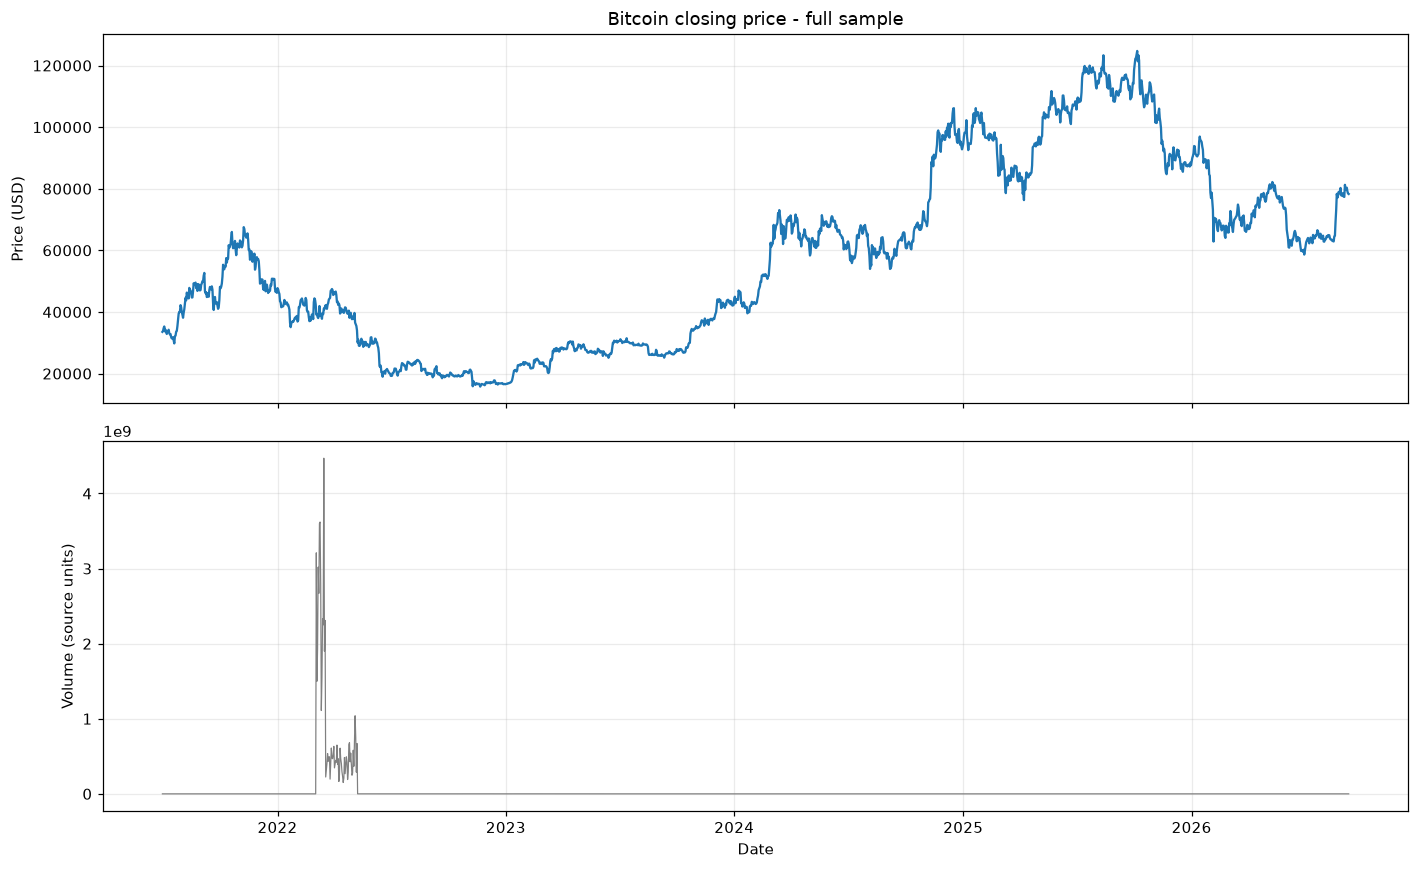

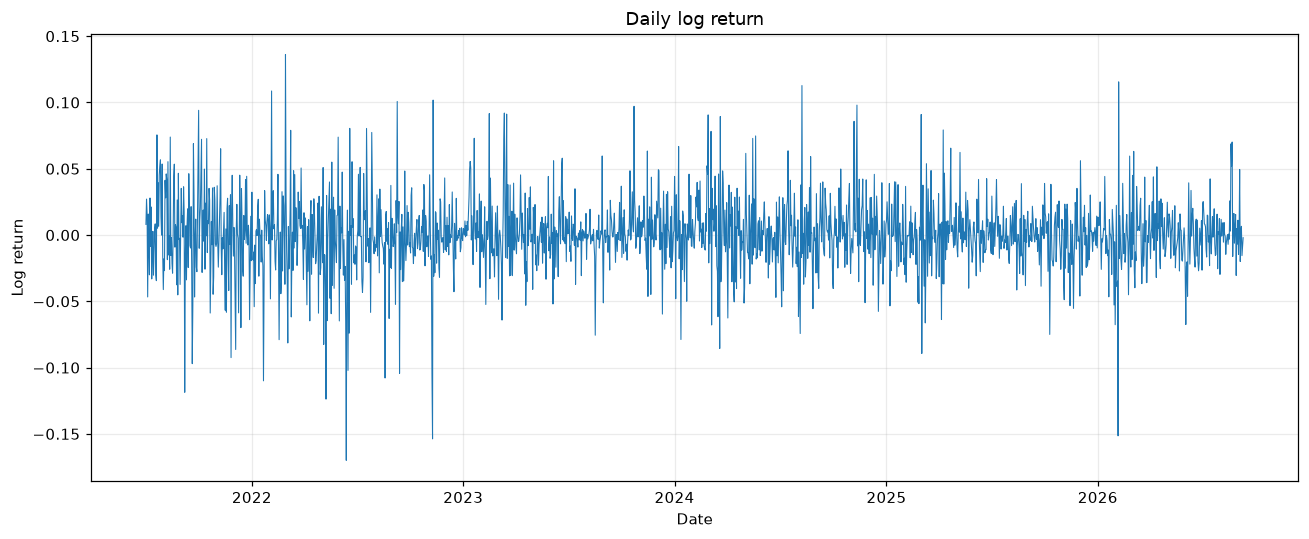

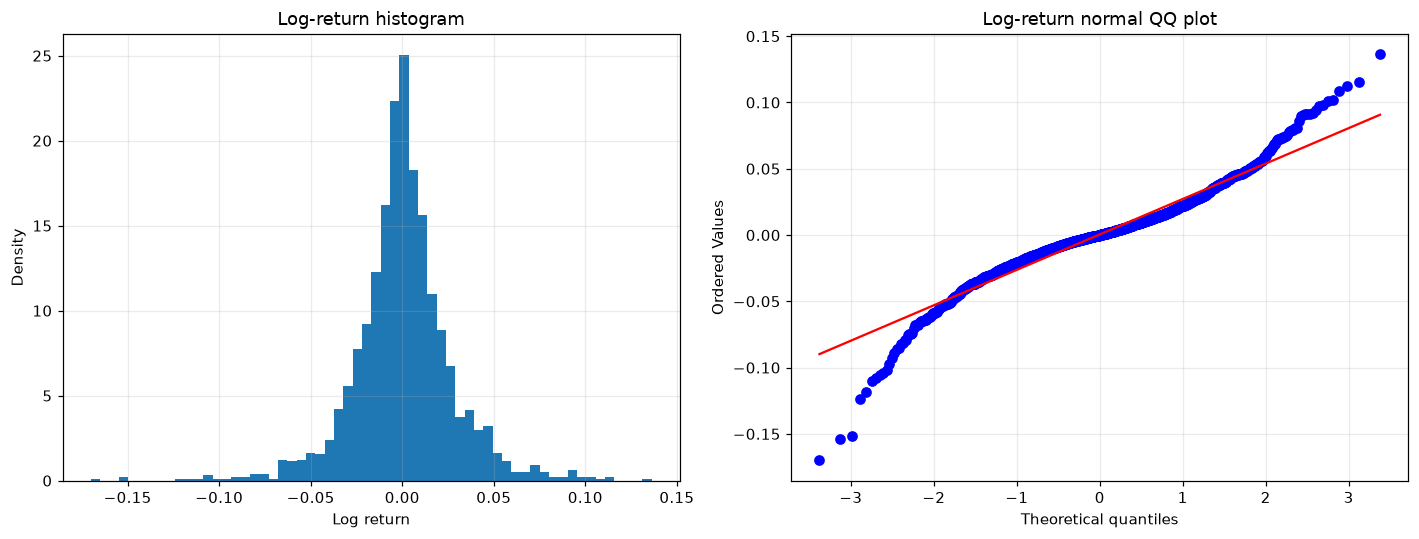

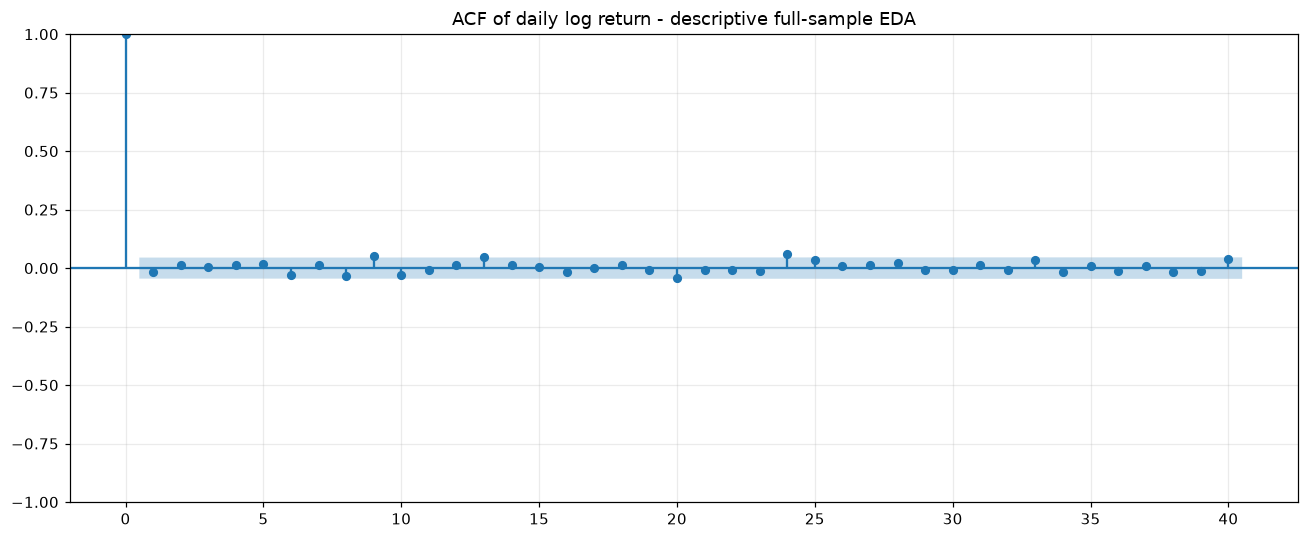

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
axes[0].plot(df.index, df['Price'])
axes[0].set(title='Bitcoin closing price - full sample', ylabel='Price (USD)')
axes[1].plot(df.index, df['Volume'], color='gray', linewidth=0.8)
axes[1].set(ylabel='Volume (source units)', xlabel='Date')
save_figure(fig, '01_raw_price_volume.png')
fig, ax = plt.subplots()
ax.plot(log_ret, linewidth=0.7)
ax.set(title='Daily log return', ylabel='Log return', xlabel='Date')
save_figure(fig, '02_log_return.png')
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(log_ret.dropna(), bins=60, density=True)
axes[0].set(title='Log-return histogram', xlabel='Log return', ylabel='Density')
stats.probplot(log_ret.dropna(), dist='norm', plot=axes[1])
axes[1].set_title('Log-return normal QQ plot')
save_figure(fig, '03_return_distribution.png')
fig, ax = plt.subplots()
plot_acf(log_ret.dropna(), lags=40, ax=ax)
ax.set_title('ACF of daily log return - descriptive full-sample EDA')
save_figure(fig, '04_acf_log_return.png')

### Descriptive Statistics

Price and observed-step log return, reported separately for the full sample,
the first 80% (Train), and the final 20% (Test), using the notebook's raw
chronological split before scaling or windowing. Columns identify each sample;
rows give units, dates, Count, Mean, SD, Min, Q1, Median, Q3, Max, Skewness,
and Excess kurtosis.

SD uses `ddof=1`; skewness and excess kurtosis use pandas' bias-corrected
estimators (normal-distribution excess kurtosis = 0). Log returns are natural-log
changes, not percentages, across successive observed dates. The first full-sample
return is undefined and excluded. Returns belong to their ending date, so the
first Test return uses the last Train price. Calendar gaps are not filled.
Full-sample and Test statistics are descriptive reporting only, not inputs to
model selection or fitting. The tables below were calculated from the supplied
source data without rerunning model training.


In [4]:
# Descriptive reporting only; this cell does not fit or configure a model.
def _make_descriptive_statistics(price, train_ratio):
    assert price.index.is_monotonic_increasing and price.index.is_unique
    assert price.notna().all() and np.isfinite(price).all() and price.gt(0).all()
    split = int(train_ratio * len(price))
    assert 0 < split < len(price)
    # Assign returns to their ending date; retain the Train-to-Test boundary return.
    log_return = np.log(price).diff()
    rows = []
    for variable, series, unit in [('Price', price, 'USD'),
                                    ('Log return', log_return, 'natural log; not percent')]:
        for sample, start, end in [('Full sample', 0, len(price)),
                                    ('Train', 0, split), ('Test', split, len(price))]:
            values = series.iloc[start:end].dropna()
            summary = values.describe(percentiles=[0.25, 0.5, 0.75])
            rows.append({'Variable': variable, 'Sample': sample, 'Unit': unit,
                'Start': str(values.index[0].date()), 'End': str(values.index[-1].date()),
                'Count': int(summary['count']), 'Mean': summary['mean'],
                'SD': summary['std'], 'Min': summary['min'], 'Q1': summary['25%'],
                'Median': summary['50%'], 'Q3': summary['75%'], 'Max': summary['max'],
                'Skewness': values.skew(), 'Excess kurtosis': values.kurt()})
    return pd.DataFrame(rows)

descriptive_statistics = _make_descriptive_statistics(df['Price'], TRAIN_RATIO)
del _make_descriptive_statistics
for _descriptive_variable in ['Price', 'Log return']:
    print(_descriptive_variable)
    display(descriptive_statistics.loc[
        descriptive_statistics['Variable'].eq(_descriptive_variable)
    ].drop(columns='Variable').set_index('Sample').T)
del _descriptive_variable

Price


Sample,Full sample,Train,Test
Unit,USD,USD,USD
Start,2021-07-01,2021-07-01,2025-08-26
End,2026-09-09,2025-08-25,2026-09-09
Count,1897,1517,380
Mean,57629.849499,51303.65056,82884.701579
SD,29376.877181,28293.431673,17763.14492
Min,15776.2,15776.2,58630.8
Q1,29798.5,27603.3,67206.375
Median,57534.6,43188.2,78230.25
Q3,78333.9,66798.7,92535.0


Log return


Sample,Full sample,Train,Test
Unit,natural log; not percent,natural log; not percent,natural log; not percent
Start,2021-07-02,2021-07-02,2025-08-26
End,2026-09-09,2025-08-25,2026-09-09
Count,1896,1516,380
Mean,0.000447,0.000784,-0.000897
SD,0.027453,0.028476,0.022908
Min,-0.169947,-0.169947,-0.151458
Q1,-0.01253,-0.012301,-0.014073
Median,-0.000094,-0.000025,-0.000511
Q3,0.013332,0.014076,0.011167


## Step 4 - Chronological Split BEFORE Scaling and Windowing


,split,start_date,end_date,n_days,price_min,price_max,price_mean,log_ret_n,log_ret_mean,log_ret_std
0,Train,2021-07-01,2025-08-25,1517,15776.2,123323.4,51303.650560,1516,0.000784,0.028476
1,Test,2025-08-26,2026-09-09,380,58630.8,124725.1,82884.701579,380,-0.000897,0.022908


Return SD above uses ddof=1; StandardScaler below uses population SD (ddof=0).


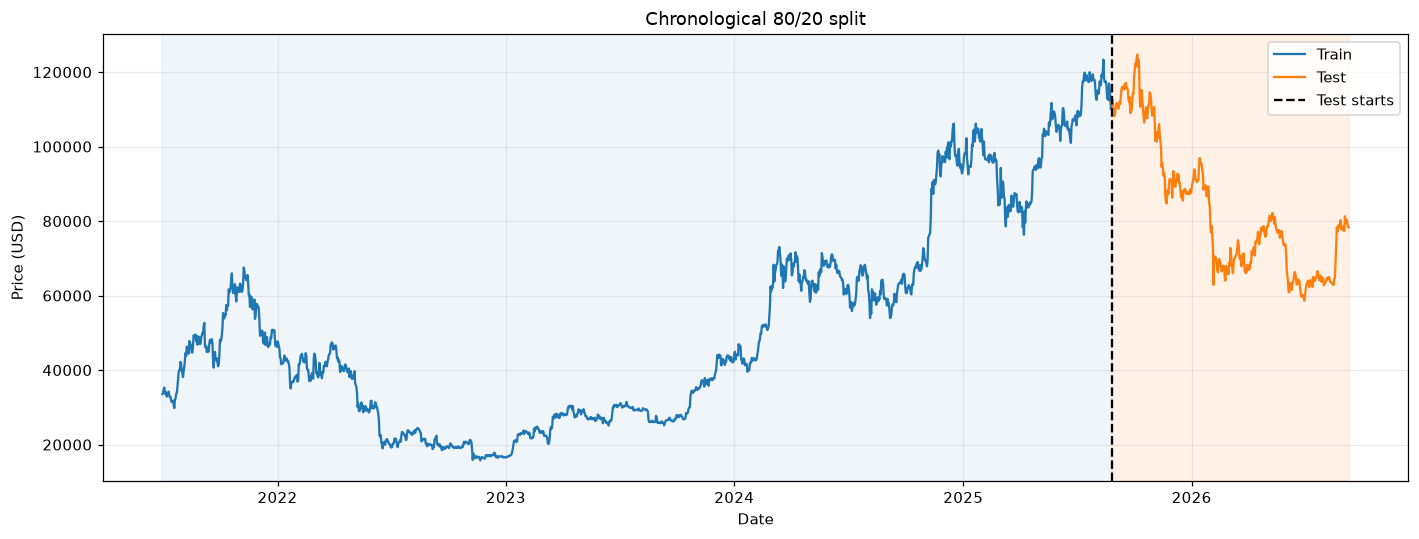

In [5]:
n = len(df)
n_train = int(TRAIN_RATIO * n)
n_test = n - n_train
TRAIN_END_IDX = n_train - 1
assert (n_train, n_test, TRAIN_END_IDX) == (1517, 380, 1516)
assert df.index[TRAIN_END_IDX] == pd.Timestamp('2025-08-25')
assert df.index[n_train] == pd.Timestamp('2025-08-26')
train_ret = log_ret.iloc[1:n_train].copy()
split_rows = []
for name, start, end in [('Train', 0, n_train), ('Test', n_train, n)]:
    prices = df['Price'].iloc[start:end]
    returns = log_ret.iloc[start:end].dropna()
    split_rows.append(dict(split=name, start_date=prices.index[0], end_date=prices.index[-1],
        n_days=len(prices), price_min=prices.min(), price_max=prices.max(), price_mean=prices.mean(),
        log_ret_n=len(returns), log_ret_mean=returns.mean(), log_ret_std=returns.std(ddof=1)))
split_summary = pd.DataFrame(split_rows)
save_table(split_summary, 'split_summary.csv')
display(split_summary)
print('Return SD above uses ddof=1; StandardScaler below uses population SD (ddof=0).')
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(df['Price'].iloc[:n_train], label='Train', color='tab:blue')
ax.plot(df['Price'].iloc[n_train:], label='Test', color='tab:orange')
ax.axvspan(df.index[0], df.index[n_train], alpha=0.07, color='tab:blue')
ax.axvspan(df.index[n_train], df.index[-1], alpha=0.10, color='tab:orange')
ax.axvline(df.index[n_train], color='black', linestyle='--', label='Test starts')
ax.set(title='Chronological 80/20 split', ylabel='Price (USD)', xlabel='Date')
ax.legend()
save_figure(fig, '05_train_test_split.png')

## Step 5 - Train-only Input Scaling
Fit scaler_x on daily return indices 1..1516 only. Transform later observations with its fixed train parameters solely for inference; test never contributes to fitting.


In [6]:
scaler_x_fit_indices = np.arange(1,n_train)
assert scaler_x_fit_indices.max() <= TRAIN_END_IDX
scaler_x = StandardScaler().fit(train_ret.to_numpy().reshape(-1,1))
assert int(scaler_x.n_samples_seen_) == n_train-1
np.testing.assert_allclose(scaler_x.mean_[0],train_ret.mean(),atol=1e-12)
np.testing.assert_allclose(scaler_x.scale_[0],train_ret.std(ddof=0),atol=1e-12)
z = np.full(n,np.nan,dtype=float)
z[1:] = scaler_x.transform(log_ret.iloc[1:].to_numpy().reshape(-1,1)).ravel()
assert np.isnan(z[0]) and np.isfinite(z[1:]).all()
scaler_x_params = dict(mean=float(scaler_x.mean_[0]),std=float(scaler_x.scale_[0]),ddof=0,
    fit_first_index=1,fit_last_index=int(scaler_x_fit_indices.max()),n_samples=int(scaler_x.n_samples_seen_))
(MODEL_DIR/'scaler_x_params.json').write_text(json.dumps(scaler_x_params,indent=2),encoding='utf-8')
joblib.dump(scaler_x,MODEL_DIR/'scaler_x.joblib')
print('Frozen input scaler:',scaler_x_params)

Frozen input scaler: {'mean': 0.0007841095418230332, 'std': 0.02846616907695721, 'ddof': 0, 'fit_first_index': 1, 'fit_last_index': 1516, 'n_samples': 1516}


## Step 6 - Direct Features and Targets per Horizon
X_t contains z[t-59..t]. y_t^(h) = log_price[t+h]-log_price[t]. Each horizon has its own train origins and target scaler.
All training feature indices and target dates lie in Train. There is no validation set.


In [7]:
training, scaler_y, provenance_rows = {}, {}, []
for h in HORIZONS:
    origins = np.arange(LOOKBACK,TRAIN_END_IDX-h+1)
    input_idx = origins[:,None]-np.arange(LOOKBACK-1,-1,-1)[None,:]
    target_idx = origins+h
    assert input_idx.min()>=1 and input_idx.max()<=TRAIN_END_IDX
    assert target_idx.max()<=TRAIN_END_IDX
    X = z[input_idx]
    y = log_price.iloc[target_idx].to_numpy()-log_price.iloc[origins].to_numpy()
    target_scaler = StandardScaler().fit(y.reshape(-1,1))
    y_scaled = target_scaler.transform(y.reshape(-1,1)).ravel()
    assert len(origins)==TRAIN_END_IDX-LOOKBACK+1-h==1457-h
    assert X.shape==(len(origins),LOOKBACK) and np.isfinite(X).all() and np.isfinite(y_scaled).all()
    assert int(target_scaler.n_samples_seen_)==len(origins)
    scaler_y[h]=target_scaler
    training[h]=dict(origins=origins,input_idx=input_idx,target_idx=target_idx,X=X,y=y,y_scaled=y_scaled)
    provenance_rows.append(dict(h=h,n_train=len(origins),input_min_idx=int(input_idx.min()),
        input_max_idx=int(input_idx.max()),target_max_idx=int(target_idx.max()),
        target_max_date=df.index[target_idx.max()],scaler_y_n=int(target_scaler.n_samples_seen_),
        scaler_y_mean=float(target_scaler.mean_[0]),scaler_y_std=float(target_scaler.scale_[0])))
provenance = pd.DataFrame(provenance_rows)
save_table(provenance,'training_provenance.csv')
display(provenance)

,h,n_train,input_min_idx,input_max_idx,target_max_idx,target_max_date,scaler_y_n,scaler_y_mean,scaler_y_std
0,1,1456,1,1515,1516,2025-08-25,1456,0.000585,0.028309
1,3,1454,1,1513,1516,2025-08-25,1454,0.001782,0.048496
2,5,1452,1,1511,1516,2025-08-25,1452,0.002938,0.063023
3,7,1450,1,1509,1516,2025-08-25,1450,0.004051,0.074769
4,14,1443,1,1502,1516,2025-08-25,1443,0.008581,0.105848
5,21,1436,1,1495,1516,2025-08-25,1436,0.013036,0.130910
6,30,1427,1,1486,1516,2025-08-25,1427,0.019431,0.157328


## Step 7 - Train-only Analytical Hyperparameters
Use exactly the supplied Cherkassky & Ma (2004) formulas, with population SD (ddof=0):
C=max(abs(mean(y_scaled)+3*std(y_scaled)),abs(mean(y_scaled)-3*std(y_scaled))).
The noise estimate uses k=3 nearest other training samples. Explicitly exclude the row's own index, including in distance ties.
This leave-one-out noise calculation is a fixed training-data formula, not SVR cross-validation or hyperparameter search.
a=n^(1/5)*k; sigma_hat=sqrt(a/(a-1)*MSE_knn); epsilon=3*sigma_hat*sqrt(log(n)/n).
Gamma uses scikit-learn's scale formula 1/(n_features*X.var()). C is expected to be approximately 3 for every horizon because each train target is standardized.


In [8]:
hyper_rows, hyperparameter_origins = [], {}
for h in HORIZONS:
    batch = training[h]
    X,y_scaled = batch['X'],batch['y_scaled']
    sample_n = len(y_scaled)
    assert batch['input_idx'].max()<=TRAIN_END_IDX and batch['target_idx'].max()<=TRAIN_END_IDX
    hyperparameter_origins[h]=batch['origins'].copy()
    y_mean,y_std = float(y_scaled.mean()),float(y_scaled.std())
    C = max(abs(y_mean+3*y_std),abs(y_mean-3*y_std))
    nn = NearestNeighbors(n_neighbors=KNN_K+1).fit(X)
    _,idx = nn.kneighbors(X)
    neighbor_idx = np.stack([neighbors[neighbors!=row][:KNN_K] for row,neighbors in enumerate(idx)])
    assert neighbor_idx.shape==(sample_n,KNN_K)
    assert (neighbor_idx!=np.arange(sample_n)[:,None]).all()
    y_hat_knn = y_scaled[neighbor_idx].mean(axis=1)
    mse_knn = np.mean((y_scaled-y_hat_knn)**2)
    a = sample_n**(1/5)*KNN_K
    sigma_hat = float(np.sqrt(a/(a-1)*mse_knn))
    epsilon = float(3*sigma_hat*np.sqrt(np.log(sample_n)/sample_n))
    gamma_value = float(1/(X.shape[1]*X.var()))
    assert C>0 and epsilon>=0 and np.isfinite([C,sigma_hat,epsilon,gamma_value]).all()
    hyper_rows.append(dict(h=h,n_train=sample_n,y_mean=y_mean,y_std=y_std,C=C,
        sigma_hat=sigma_hat,epsilon=epsilon,gamma_value=gamma_value))
hyperparameters = pd.DataFrame(hyper_rows)
save_table(hyperparameters,'svr_hyperparameters.csv')
display(hyperparameters)

,h,n_train,y_mean,y_std,C,sigma_hat,epsilon,gamma_value
0,1,1456,9.760202e-18,1.0,3.0,1.129543,0.239669,0.016509
1,3,1454,0.000000e+00,1.0,3.0,1.147405,0.243603,0.016492
2,5,1452,-1.957418e-17,1.0,3.0,1.136583,0.241449,0.016476
3,7,1450,-9.800589e-18,1.0,3.0,1.139181,0.242145,0.016460
4,14,1443,1.969626e-17,1.0,3.0,1.129390,0.240565,0.016401
5,21,1436,0.000000e+00,1.0,3.0,1.133680,0.241986,0.016340
6,30,1427,3.983421e-17,1.0,3.0,1.136511,0.243249,0.016266


<a id="svr-top5-train"></a>

### 7.1 — SVR Top 5 parameter sets per horizon (Train RMSE only)

The user-requested experiment keeps the chronological Train/Test 80/20 split and no validation or cross-validation. Test and supplied future actuals never enter candidate fitting, ranking, tie-breaking or selection. Each horizon uses 27 fixed combinations: C, epsilon and gamma multipliers 0.5/1/2 around its original Train-derived analytical settings. Kernel and lookback remain unchanged. All 30 daily-path horizons follow the same search rule.

Show **five distinct parameter sets for each of h=1,3,5,7,14,21,30**, ranked by Train RMSE in original price units; ties use candidate ID. Train MAPE is descriptive only. Rank 1 is fixed before Test. A low in-sample RMSE does not establish the best model for new observations. The existing Test and future-actual periods have already been inspected: this rerun is a retrospective experiment, not a new untouched holdout.


Epsilon is measured on standardized cumulative log-return targets; it is not a price or a price percentage. Only Train RMSE is expressed in original price units.


In [9]:
# All candidate fitting/ranking uses only the original Train 80%.
from itertools import product
svr_search_root = next(base for base in [Path.cwd(), *Path.cwd().parents]
    if (base / 'CSV').is_dir() and (base / 'ACTUAL_FOR_PREDICT').is_dir())
svr_search_output = svr_search_root / 'OUTPUT' / 'SVR_TRAIN_SEARCH' / 'BTC'
svr_search_table_dir = svr_search_output / 'tables'
svr_search_summary_dir = svr_search_output / 'summaries'
for svr_directory in [svr_search_table_dir, svr_search_summary_dir]:
    svr_directory.mkdir(parents=True, exist_ok=True)
svr_search_train_end = n_train - 1
svr_search_k = KNN_K
svr_search_kernel = KERNEL
assert svr_search_kernel == 'rbf'
svr_search_rows = []
svr_search_log_price = np.asarray(log_price, dtype=float)
svr_search_prices = df['Price'].to_numpy(dtype=float)
svr_search_origins = {}
for svr_h in range(1, max(HORIZONS) + 1):
    svr_origins = np.arange(LOOKBACK, n_train-svr_h)
    svr_indices = svr_origins[:, None]-np.arange(LOOKBACK-1, -1, -1)[None, :]
    svr_targets = svr_origins+svr_h
    assert svr_targets.max() == svr_search_train_end
    assert svr_indices.min() >= 1 and (svr_indices <= svr_origins[:, None]).all()
    assert len(svr_origins) == n_train-LOOKBACK-svr_h
    svr_search_origins[svr_h] = svr_origins.copy()
    svr_X = z[svr_indices]
    svr_y = svr_search_log_price[svr_targets]-svr_search_log_price[svr_origins]
    svr_y_scaler = StandardScaler().fit(svr_y[:, None])
    svr_ys = svr_y_scaler.transform(svr_y[:, None]).ravel()
    assert np.isfinite(svr_X).all() and np.isfinite(svr_ys).all()
    svr_base_C = max(abs(svr_ys.mean()+3*svr_ys.std(ddof=0)), abs(svr_ys.mean()-3*svr_ys.std(ddof=0)))
    svr_neighbors = NearestNeighbors(n_neighbors=svr_search_k+1).fit(svr_X).kneighbors(svr_X, return_distance=False)
    svr_others = np.stack([indices[indices != i][:svr_search_k] for i, indices in enumerate(svr_neighbors)])
    assert (svr_others != np.arange(len(svr_y))[:, None]).all()
    svr_knn_mse = np.mean((svr_ys-svr_ys[svr_others].mean(axis=1))**2)
    svr_a = len(svr_y)**0.2*svr_search_k
    svr_sigma = float(np.sqrt(svr_a/(svr_a-1)*svr_knn_mse))
    svr_base_epsilon = float(3*svr_sigma*np.sqrt(np.log(len(svr_y))/len(svr_y)))
    svr_base_gamma = float(1/(svr_X.shape[1]*svr_X.var()))
    svr_grid = list(product(SVR_SEARCH_CONFIG['C_multipliers'],
        SVR_SEARCH_CONFIG['epsilon_multipliers'], SVR_SEARCH_CONFIG['gamma_multipliers']))
    assert len(svr_grid) == 27
    for svr_id, (svr_cm, svr_em, svr_gm) in enumerate(svr_grid, start=1):
        svr_C, svr_epsilon, svr_gamma = svr_base_C*svr_cm, svr_base_epsilon*svr_em, svr_base_gamma*svr_gm
        svr_candidate = SVR(kernel=svr_search_kernel, C=svr_C, epsilon=svr_epsilon, gamma=svr_gamma)
        svr_row = dict(asset='BTC', h=svr_h, candidate_id=svr_id, kernel=svr_search_kernel,
            lookback=LOOKBACK, C=svr_C, epsilon=svr_epsilon, gamma=svr_gamma,
            C_multiplier=svr_cm, epsilon_multiplier=svr_em, gamma_multiplier=svr_gm,
            base_C=svr_base_C, base_epsilon=svr_base_epsilon, base_gamma=svr_base_gamma,
            sigma_hat=svr_sigma, n_train=len(svr_y),
            first_train_target_date=df.index[svr_targets.min()], last_train_target_date=df.index[svr_targets.max()],
            Train_RMSE=np.nan, Train_MAPE_percent=np.nan, train_RMSE_scaled=np.nan,
            fit_status=-1, convergence_warning=False, eligible=False, warnings='')
        try:
            with warnings.catch_warnings(record=True) as svr_caught:
                warnings.simplefilter('always')
                svr_candidate.fit(svr_X, svr_ys)
            svr_pred_scaled = svr_candidate.predict(svr_X)
            svr_pred_return = svr_y_scaler.inverse_transform(svr_pred_scaled[:, None]).ravel()
            svr_pred_price = svr_search_prices[svr_origins]*np.exp(svr_pred_return)
            svr_actual_price = svr_search_prices[svr_targets]
            svr_convergence_warning = any(issubclass(w.category, ConvergenceWarning) for w in svr_caught)
            svr_eligible = (svr_candidate.fit_status_ == 0 and not svr_convergence_warning
                and np.isfinite(svr_pred_price).all() and (svr_pred_price > 0).all())
            svr_row.update(fit_status=int(svr_candidate.fit_status_), convergence_warning=svr_convergence_warning,
                eligible=bool(svr_eligible), support_vectors=int(svr_candidate.n_support_.sum()),
                warnings=' | '.join(str(w.message) for w in svr_caught))
            if svr_eligible:
                svr_row.update(Train_RMSE=float(np.sqrt(np.mean((svr_actual_price-svr_pred_price)**2))),
                    Train_MAPE_percent=float(100*np.mean(np.abs((svr_actual_price-svr_pred_price)/svr_actual_price))),
                    train_RMSE_scaled=float(np.sqrt(np.mean((svr_ys-svr_pred_scaled)**2))))
        except Exception as svr_error:
            svr_row['warnings'] = type(svr_error).__name__+': '+str(svr_error)
        svr_search_rows.append(svr_row)
    print(f'Train-only SVR search h={svr_h}: 27 candidate fits complete', flush=True)
svr_search_results = pd.DataFrame(svr_search_rows)
svr_search_eligible = svr_search_results.loc[svr_search_results.eligible].sort_values(
    ['h', 'Train_RMSE', 'candidate_id'], kind='stable').copy()
svr_search_eligible['rank'] = svr_search_eligible.groupby('h').cumcount()+1
assert svr_search_eligible.groupby('h').size().ge(SVR_SEARCH_CONFIG['top_n']).all()
svr_top5_all_horizons = svr_search_eligible.loc[svr_search_eligible['rank'].le(SVR_SEARCH_CONFIG['top_n'])].copy()
svr_top5_requested = svr_top5_all_horizons.loc[svr_top5_all_horizons.h.isin(HORIZONS)].copy()
svr_selected_parameters = svr_search_eligible.loc[svr_search_eligible['rank'].eq(1)].set_index('h')
assert len(svr_selected_parameters) == max(HORIZONS)
assert svr_top5_requested.groupby('h').size().eq(5).all()
assert not svr_top5_requested.duplicated(['h', 'C', 'epsilon', 'gamma']).any()
assert pd.to_datetime(svr_top5_all_horizons.last_train_target_date).le(df.index[n_train-1]).all()
for svr_name, svr_frame in [('all_candidates.csv', svr_search_results), ('top5_all_30_horizons.csv', svr_top5_all_horizons),
        ('top5_requested_horizons.csv', svr_top5_requested), ('selected_rank1_parameters.csv', svr_selected_parameters.reset_index())]:
    svr_frame.to_csv(svr_search_table_dir / svr_name, index=False, encoding='utf-8-sig')
    save_table(svr_frame, 'svr_search_'+svr_name)
svr_search_design = dict(SVR_SEARCH_CONFIG, asset='BTC', horizons=HORIZONS, searched_horizons=list(range(1, max(HORIZONS)+1)),
    lookback=LOOKBACK, train_end=str(df.index[n_train-1].date()), test_start=str(df.index[n_train].date()),
    candidate_count_per_horizon=27, selection_scope='Train rows only, per horizon',
    selection_metric_unit='USD', selection_tie_break='candidate_id ascending',
    warning='In-sample fitting ranking, not validation or generalization evidence; Test/future periods were previously inspected.')
(svr_search_summary_dir / 'search_design.json').write_text(json.dumps(svr_search_design, indent=2), encoding='utf-8')
display(Markdown('**Top 5 distinct SVR parameter sets per requested horizon — Train fit only**'))
svr_top5_columns = ['rank', 'candidate_id', 'kernel', 'lookback', 'C', 'epsilon', 'gamma',
    'Train_RMSE', 'Train_MAPE_percent', 'n_train', 'fit_status']
for svr_h in HORIZONS:
    display(Markdown(f'**h={svr_h}: Train RMSE ({'USD'}), MAPE (%) — not Test scores**'))
    display(HTML(svr_top5_requested.loc[svr_top5_requested.h.eq(svr_h), svr_top5_columns].to_html(
        index=False, float_format=lambda value: f'{value:,.8f}')))
display(Markdown('**Rank 1 is fixed for every horizon before any Test/future evaluation.**'))
print('Search:', len(svr_search_results), 'candidate fits; requested Top-5 rows:', len(svr_top5_requested))


Train-only SVR search h=1: 27 candidate fits complete


Train-only SVR search h=2: 27 candidate fits complete


Train-only SVR search h=3: 27 candidate fits complete


Train-only SVR search h=4: 27 candidate fits complete


Train-only SVR search h=5: 27 candidate fits complete


Train-only SVR search h=6: 27 candidate fits complete


... (37 outputs left out)

**h=30: Train RMSE (USD), MAPE (%) — not Test scores**

rank,candidate_id,kernel,lookback,C,epsilon,gamma,Train_RMSE,Train_MAPE_percent,n_train,fit_status
1,21,rbf,60,6.00000000,0.12162440,0.03253287,"1,094.25194209",1.80965587,1427,0
2,12,rbf,60,3.00000000,0.12162440,0.03253287,"1,248.25490659",1.86632568,1427,0
3,20,rbf,60,6.00000000,0.12162440,0.01626643,"1,670.11448517",2.12968978,1427,0
4,24,rbf,60,6.00000000,0.24324880,0.03253287,"2,090.03115970",3.40562907,1427,0
5,15,rbf,60,3.00000000,0.24324880,0.03253287,"2,137.61858899",3.42832900,1427,0


**Rank 1 is fixed for every horizon before any Test/future evaluation.**

Search: 810 candidate fits; requested Top-5 rows: 35


## Step 8 - Fit the Train-ranked selected models and freeze parameters


In [10]:
# Apply rank-1 Train selections; analytical base values remain in the search archive.
for h in HORIZONS:
    chosen = svr_selected_parameters.loc[h]
    for column, selected_column in [('C','C'), ('epsilon','epsilon'), ('gamma_value','gamma')]:
        hyperparameters.loc[hyperparameters.h.eq(h), column] = float(chosen[selected_column])
models,fit_records,frozen_hashes = {},[],{}
for h in HORIZONS:
    row = hyperparameters.set_index('h').loc[h]
    batch = training[h]
    svr_chosen = svr_selected_parameters.loc[h]
    C, epsilon, gamma_value = (float(svr_chosen[k]) for k in ['C', 'epsilon', 'gamma'])
    model = SVR(kernel=KERNEL, C=C, epsilon=epsilon, gamma=gamma_value)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(batch['X'],batch['y_scaled'])
    convergence_warning = any(issubclass(w.category,ConvergenceWarning) for w in caught)
    sv_count = int(model.n_support_.sum())
    sv_pct = 100*sv_count/len(batch['X'])
    train_rmse_scaled = float(np.sqrt(np.mean((batch['y_scaled']-model.predict(batch['X']))**2)))
    np.testing.assert_allclose(model._gamma,row['gamma_value'],rtol=1e-12)
    assert model.shape_fit_[0]==len(batch['origins'])
    models[h]=model
    joblib.dump(model,MODEL_DIR/f'svr_h{h}.joblib')
    joblib.dump(scaler_y[h],MODEL_DIR/f'scaler_y_h{h}.joblib')
    frozen_hashes[h]=joblib.hash((model,scaler_x,scaler_y[h]))
    fit_records.append(dict(h=h,n_SV=sv_count,SV_pct=sv_pct,train_RMSE_scaled=train_rmse_scaled,
        fit_status=int(model.fit_status_),convergence_warning=convergence_warning,
        warnings=' | '.join(str(w.message) for w in caught)))
    print(f'Fitted h={h}: {sv_count} support vectors ({sv_pct:.2f}%)',flush=True)
fit_audit = pd.DataFrame(fit_records)
hyperparameters = hyperparameters.merge(fit_audit,on='h',validate='one_to_one')
save_table(hyperparameters,'svr_hyperparameters.csv')
display(hyperparameters)
assert not fit_audit['convergence_warning'].any()
assert fit_audit['fit_status'].eq(0).all() and fit_audit['SV_pct'].between(0,100).all()

Fitted h=1: 1247 support vectors (85.65%)


Fitted h=3: 1264 support vectors (86.93%)


Fitted h=5: 1278 support vectors (88.02%)


Fitted h=7: 1285 support vectors (88.62%)


Fitted h=14: 1258 support vectors (87.18%)


Fitted h=21: 1276 support vectors (88.86%)


Fitted h=30: 1268 support vectors (88.86%)


,h,n_train,y_mean,y_std,C,sigma_hat,epsilon,gamma_value,n_SV,SV_pct,train_RMSE_scaled,fit_status,convergence_warning,warnings
0,1,1456,9.760202e-18,1.0,6.0,1.129543,0.119835,0.033017,1247,85.645604,0.118900,0,False,
1,3,1454,0.000000e+00,1.0,6.0,1.147405,0.121802,0.032985,1264,86.932600,0.120585,0,False,
2,5,1452,-1.957418e-17,1.0,6.0,1.136583,0.120725,0.032952,1278,88.016529,0.116850,0,False,
3,7,1450,-9.800589e-18,1.0,6.0,1.139181,0.121072,0.032919,1285,88.620690,0.116680,0,False,
4,14,1443,1.969626e-17,1.0,6.0,1.129390,0.120283,0.032801,1258,87.179487,0.115195,0,False,
5,21,1436,0.000000e+00,1.0,6.0,1.133680,0.120993,0.032681,1276,88.857939,0.116420,0,False,
6,30,1427,3.983421e-17,1.0,6.0,1.136511,0.121624,0.032533,1268,88.857744,0.117132,0,False,


## Step 9 - Rolling-origin Test Forecasts with Fixed Models
Origins are 1516..1895; each input uses only the previous 60 observed returns through its own origin.
Each horizon predicts eligible origins in one batch. Inverse-transform its cumulative-return target, then multiply the origin price by exp(predicted cumulative return).
No model, scaler, or hyperparameter is re-estimated during inference.


In [11]:
test_origins = np.arange(TRAIN_END_IDX,n-1)
forecast_rows,predicted_cumulative_returns = [],{}
for h in HORIZONS:
    origins = test_origins[test_origins+h<n]
    input_idx = origins[:,None]-np.arange(LOOKBACK-1,-1,-1)[None,:]
    assert (input_idx<=origins[:,None]).all() and input_idx.min()>=1
    X_test = z[input_idx]
    assert joblib.hash((models[h],scaler_x,scaler_y[h]))==frozen_hashes[h]
    y_hat_scaled = models[h].predict(X_test)
    r_hat = scaler_y[h].inverse_transform(y_hat_scaled.reshape(-1,1)).ravel()
    predicted_cumulative_returns[h]=r_hat
    prices_origin = df['Price'].iloc[origins].to_numpy()
    prices_hat = prices_origin*np.exp(r_hat)
    for pos,origin in enumerate(origins):
        forecast_rows.append(dict(origin_date=df.index[origin],h=h,target_date=df.index[origin+h],
            price_origin=prices_origin[pos],actual=df['Price'].iloc[origin+h],svr_fc=prices_hat[pos]))
    assert joblib.hash((models[h],scaler_x,scaler_y[h]))==frozen_hashes[h]
forecasts = pd.DataFrame(forecast_rows).sort_values(['h','target_date']).reset_index(drop=True)
assert forecasts.groupby('h').size().to_dict()=={h:n_test-h+1 for h in HORIZONS}
assert not forecasts.duplicated(['origin_date','h']).any()
assert ((forecasts['target_date']-forecasts['origin_date']).dt.days==forecasts['h']).all()
assert forecasts['target_date'].between(df.index[n_train],df.index[-1]).all()
save_table(forecasts,'forecasts_long.csv')
display(forecasts.groupby('h').size().rename('n_points').to_frame())

,n_points
h,
1,380
3,378
5,376
7,374
14,367
21,360
30,351


### 9.1 Test Forecast Tables by Horizon


In [12]:
for h in HORIZONS:
    group = forecasts.loc[forecasts['h'].eq(h)].copy()
    save_table(group,f'forecasts_h{h}.csv')
    display(Markdown(f'**h={h} days, {len(group)} test forecasts**'))
    show_scroll_table(group)

**h=1 days, 380 test forecasts**

origin_date,h,target_date,price_origin,actual,svr_fc
2025-08-25,1,2025-08-26,"110,118.40","111,768.60","111,042.17"
2025-08-26,1,2025-08-27,"111,768.60","111,255.60","111,641.00"
2025-08-27,1,2025-08-28,"111,255.60","112,568.90","109,602.13"
2025-08-28,1,2025-08-29,"112,568.90","108,355.60","115,169.36"
2025-08-29,1,2025-08-30,"108,355.60","108,818.10","109,110.57"
2025-08-30,1,2025-08-31,"108,818.10","108,226.80","109,158.24"
2025-08-31,1,2025-09-01,"108,226.80","109,243.30","107,165.93"
2025-09-01,1,2025-09-02,"109,243.30","111,218.30","109,559.45"
2025-09-02,1,2025-09-03,"111,218.30","111,716.50","111,217.36"
2025-09-03,1,2025-09-04,"111,716.50","110,712.70","115,117.93"


**h=3 days, 378 test forecasts**

origin_date,h,target_date,price_origin,actual,svr_fc
2025-08-25,3,2025-08-28,"110,118.40","112,568.90","108,725.38"
2025-08-26,3,2025-08-29,"111,768.60","108,355.60","112,384.09"
2025-08-27,3,2025-08-30,"111,255.60","108,818.10","113,798.19"
2025-08-28,3,2025-08-31,"112,568.90","108,226.80","117,697.10"
2025-08-29,3,2025-09-01,"108,355.60","109,243.30","108,233.04"
2025-08-30,3,2025-09-02,"108,818.10","111,218.30","107,019.72"
2025-08-31,3,2025-09-03,"108,226.80","111,716.50","107,258.15"
2025-09-01,3,2025-09-04,"109,243.30","110,712.70","113,318.24"
2025-09-02,3,2025-09-05,"111,218.30","110,652.20","113,980.29"
2025-09-03,3,2025-09-06,"111,716.50","110,194.40","116,981.91"


**h=5 days, 376 test forecasts**

origin_date,h,target_date,price_origin,actual,svr_fc
2025-08-25,5,2025-08-30,"110,118.40","108,818.10","112,347.06"
2025-08-26,5,2025-08-31,"111,768.60","108,226.80","114,413.12"
2025-08-27,5,2025-09-01,"111,255.60","109,243.30","113,459.24"
2025-08-28,5,2025-09-02,"112,568.90","111,218.30","117,698.33"
2025-08-29,5,2025-09-03,"108,355.60","111,716.50","107,806.54"
2025-08-30,5,2025-09-04,"108,818.10","110,712.70","111,078.60"
2025-08-31,5,2025-09-05,"108,226.80","110,652.20","109,422.54"
2025-09-01,5,2025-09-06,"109,243.30","110,194.40","114,687.27"
2025-09-02,5,2025-09-07,"111,218.30","111,150.10","115,177.59"
2025-09-03,5,2025-09-08,"111,716.50","112,068.40","114,633.55"


... (4 outputs left out)

**h=21 days, 360 test forecasts**

origin_date,h,target_date,price_origin,actual,svr_fc
2025-08-25,21,2025-09-15,"110,118.40","115,362.10","120,602.98"
2025-08-26,21,2025-09-16,"111,768.60","116,795.90","123,125.72"
2025-08-27,21,2025-09-17,"111,255.60","116,425.90","121,593.34"
2025-08-28,21,2025-09-18,"112,568.90","117,086.00","122,932.71"
2025-08-29,21,2025-09-19,"108,355.60","115,649.00","112,673.91"
2025-08-30,21,2025-09-20,"108,818.10","115,699.20","111,900.97"
2025-08-31,21,2025-09-21,"108,226.80","115,243.00","110,300.91"
2025-09-01,21,2025-09-22,"109,243.30","112,673.00","112,150.58"
2025-09-02,21,2025-09-23,"111,218.30","112,002.60","114,349.72"
2025-09-03,21,2025-09-24,"111,716.50","113,307.10","113,705.40"


**h=30 days, 351 test forecasts**

origin_date,h,target_date,price_origin,actual,svr_fc
2025-08-25,30,2025-09-24,"110,118.40","113,307.10","115,822.08"
2025-08-26,30,2025-09-25,"111,768.60","109,016.30","115,962.51"
2025-08-27,30,2025-09-26,"111,255.60","109,662.20","117,507.71"
2025-08-28,30,2025-09-27,"112,568.90","109,652.80","119,274.29"
2025-08-29,30,2025-09-28,"108,355.60","112,174.60","110,822.33"
2025-08-30,30,2025-09-29,"108,818.10","114,357.50","110,971.46"
2025-08-31,30,2025-09-30,"108,226.80","114,048.50","110,272.36"
2025-09-01,30,2025-10-01,"109,243.30","118,576.20","112,641.31"
2025-09-02,30,2025-10-02,"111,218.30","120,566.10","116,334.32"
2025-09-03,30,2025-10-03,"111,716.50","122,224.20","115,490.10"


### 9.2 Future Forecasts from the Last Observed Date
One row per horizon uses a common latest origin. These future targets have no actual prices in the source and are excluded from test metrics.
These are fixed-model point forecasts; no prediction interval is claimed.


In [13]:
latest_input = z[n-LOOKBACK:n].reshape(1,LOOKBACK)
future_rows=[]
for h in HORIZONS:
    predicted_scaled = models[h].predict(latest_input)
    r_hat = float(scaler_y[h].inverse_transform(predicted_scaled.reshape(-1,1))[0,0])
    future_rows.append(dict(origin_date=df.index[-1],h=h,target_date=df.index[-1]+pd.Timedelta(days=h),
        price_origin=float(df['Price'].iloc[-1]),svr_fc=float(df['Price'].iloc[-1])*np.exp(r_hat)))
    assert joblib.hash((models[h],scaler_x,scaler_y[h]))==frozen_hashes[h]
future_forecasts = pd.DataFrame(future_rows)
save_table(future_forecasts,'future_forecast_by_horizon.csv')
show_scroll_table(future_forecasts)

C:\Users\User\AppData\Local\Temp\ipykernel_29164\555769745.py:6: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  future_rows.append(dict(origin_date=df.index[-1],h=h,target_date=df.index[-1]+pd.Timedelta(days=h),
C:\Users\User\AppData\Local\Temp\ipykernel_29164\555769745.py:6: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  future_rows.append(dict(origin_date=df.index[-1],h=h,target_date=df.index[-1]+pd.Timedelta(days=h),
C:\Users\User\AppData\Local\Temp\ipykernel_29164\555769745.py:6: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 

origin_date,h,target_date,price_origin,svr_fc
2026-09-09,1,2026-09-10,"78,297.00","77,704.58"
2026-09-09,3,2026-09-12,"78,297.00","78,177.78"
2026-09-09,5,2026-09-14,"78,297.00","78,481.90"
2026-09-09,7,2026-09-16,"78,297.00","79,868.42"
2026-09-09,14,2026-09-23,"78,297.00","83,043.84"
2026-09-09,21,2026-09-30,"78,297.00","82,846.36"
2026-09-09,30,2026-10-09,"78,297.00","83,218.76"


### 9.3 Daily future forecast tables - next 7 and 30 calendar days
Direct cumulative-return forecasts for every day. Reuses existing horizon models; fits only missing horizons using the original Train-only prescription and fixed settings. No interpolation, validation, Test tuning or refitting of existing models.

All rows share the last observed origin. Prices are in USD. These models do not supply calibrated 95% prediction intervals.
Exports: `tables/future_forecast_daily_7d.csv` and `tables/future_forecast_daily_30d.csv` under this notebook's output directory.


In [14]:
daily_steps = max(DAILY_FORECAST_WINDOWS)
latest_origin = pd.Timestamp(df.index[-1])
latest_price = float(df['Price'].iloc[-1])
daily_dates = pd.DatetimeIndex([
    pd.Timestamp(latest_origin.to_datetime64() + np.timedelta64(h, 'D'))
    for h in range(1, daily_steps + 1)
])
# Fit only missing direct horizons, using the original Train-only prescription.
# Existing horizon estimators and scalers are reused unchanged.
daily_models = {h: models[h] for h in HORIZONS}
daily_scalers_y = {h: scaler_y[h] for h in HORIZONS}
daily_hashes = {h: frozen_hashes[h] for h in HORIZONS}
daily_fit_rows = []
for h in range(1, daily_steps + 1):
    if h in models:
        continue
    origins = np.arange(LOOKBACK, TRAIN_END_IDX - h + 1)
    input_idx = origins[:, None] - np.arange(LOOKBACK - 1, -1, -1)[None, :]
    target_idx = origins + h
    assert input_idx.min() >= 1 and target_idx.max() <= TRAIN_END_IDX
    assert (input_idx <= origins[:, None]).all()
    X = z[input_idx]
    y = log_price.iloc[target_idx].to_numpy() - log_price.iloc[origins].to_numpy()
    target_scaler = StandardScaler().fit(y.reshape(-1, 1))
    y_scaled = target_scaler.transform(y.reshape(-1, 1)).ravel()
    sample_n = len(y_scaled)
    assert np.isfinite(X).all() and np.isfinite(y_scaled).all()
    assert int(target_scaler.n_samples_seen_) == sample_n
    y_mean, y_std = float(y_scaled.mean()), float(y_scaled.std())
    C = max(abs(y_mean + 3*y_std), abs(y_mean - 3*y_std))
    nn = NearestNeighbors(n_neighbors=KNN_K + 1).fit(X)
    _, idx = nn.kneighbors(X)
    neighbor_idx = np.stack([neighbors[neighbors != row][:KNN_K]
                             for row, neighbors in enumerate(idx)])
    assert neighbor_idx.shape == (sample_n, KNN_K)
    assert (neighbor_idx != np.arange(sample_n)[:, None]).all()
    mse_knn = np.mean((y_scaled - y_scaled[neighbor_idx].mean(axis=1))**2)
    a = sample_n**(1/5) * KNN_K
    sigma_hat = float(np.sqrt(a/(a-1) * mse_knn))
    epsilon = float(3*sigma_hat*np.sqrt(np.log(sample_n)/sample_n))
    gamma_value = float(1/(X.shape[1]*X.var()))
    assert C > 0 and epsilon >= 0 and np.isfinite([C, epsilon, sigma_hat, gamma_value]).all()
    svr_chosen = svr_selected_parameters.loc[h]
    C, epsilon, gamma_value = (float(svr_chosen[k]) for k in ['C', 'epsilon', 'gamma'])
    model = SVR(kernel=KERNEL, C=C, epsilon=epsilon, gamma=gamma_value)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(X, y_scaled)
    convergence_warning = any(issubclass(w.category, ConvergenceWarning) for w in caught)
    assert model.fit_status_ == 0 and not convergence_warning
    np.testing.assert_allclose(model._gamma, gamma_value, rtol=1e-12)
    daily_models[h], daily_scalers_y[h] = model, target_scaler
    daily_hashes[h] = joblib.hash((model, scaler_x, target_scaler))
    joblib.dump(model, MODEL_DIR/f'svr_h{h}.joblib')
    joblib.dump(target_scaler, MODEL_DIR/f'scaler_y_h{h}.joblib')
    daily_fit_rows.append(dict(h=h, n_train=sample_n, target_max_idx=int(target_idx.max()),
        target_max_date=df.index[target_idx.max()], C=C, epsilon=epsilon,
        sigma_hat=sigma_hat, gamma_value=gamma_value, fit_status=int(model.fit_status_),
        convergence_warning=convergence_warning,
        warnings=' | '.join(str(w.message) for w in caught)))
save_table(pd.DataFrame(daily_fit_rows), 'daily_additional_fit_audit.csv')
latest_input = z[n-LOOKBACK:n].reshape(1, LOOKBACK)
daily_values = []
for h in range(1, daily_steps + 1):
    model, target_scaler = daily_models[h], daily_scalers_y[h]
    assert joblib.hash((model, scaler_x, target_scaler)) == daily_hashes[h]
    predicted_scaled = model.predict(latest_input)
    r_hat = float(target_scaler.inverse_transform(predicted_scaled.reshape(-1, 1))[0, 0])
    daily_values.append(latest_price*np.exp(r_hat))
    assert joblib.hash((model, scaler_x, target_scaler)) == daily_hashes[h]
future_forecast_daily = pd.DataFrame(dict(origin_date=latest_origin,
    h=np.arange(1, daily_steps + 1), target_date=daily_dates,
    day_of_week=daily_dates.day_name(), price_origin=latest_price, svr_fc=daily_values))
daily_forecast_columns = ['svr_fc']
assert len(future_forecast_daily) == daily_steps
assert ((future_forecast_daily['target_date'] - latest_origin).dt.days == future_forecast_daily['h']).all()
assert not future_forecast_daily['target_date'].duplicated().any()
values = future_forecast_daily[daily_forecast_columns].to_numpy()
assert np.isfinite(values).all() and (values > 0).all()
np.testing.assert_allclose(
    future_forecast_daily.set_index('h').loc[HORIZONS, daily_forecast_columns],
    future_forecasts.set_index('h').loc[HORIZONS, daily_forecast_columns], rtol=1e-12)
future_daily_tables = {}
for days in DAILY_FORECAST_WINDOWS:
    table = future_forecast_daily.iloc[:days].copy()
    assert len(table) == days and table['h'].tolist() == list(range(1, days + 1))
    future_daily_tables[days] = table
    save_table(table, f'future_forecast_daily_{days}d.csv')
    display(Markdown(f'**Next {days} calendar days - origin {latest_origin.date()}, last price {latest_price:,.2f} USD**'))
    shown = table.copy()
    for column in ['origin_date', 'target_date']:
        shown[column] = shown[column].dt.strftime('%Y-%m-%d')
    display(HTML(shown.to_html(index=False, float_format=lambda value: f'{value:,.2f}')))

**Next 7 calendar days - origin 2026-09-09, last price 78,297.00 USD**

origin_date,h,target_date,day_of_week,price_origin,svr_fc
2026-09-09,1,2026-09-10,Thursday,"78,297.00","77,704.58"
2026-09-09,2,2026-09-11,Friday,"78,297.00","77,816.59"
2026-09-09,3,2026-09-12,Saturday,"78,297.00","78,177.78"
2026-09-09,4,2026-09-13,Sunday,"78,297.00","78,873.59"
2026-09-09,5,2026-09-14,Monday,"78,297.00","78,481.90"
2026-09-09,6,2026-09-15,Tuesday,"78,297.00","79,648.68"
2026-09-09,7,2026-09-16,Wednesday,"78,297.00","79,868.42"


**Next 30 calendar days - origin 2026-09-09, last price 78,297.00 USD**

origin_date,h,target_date,day_of_week,price_origin,svr_fc
2026-09-09,1,2026-09-10,Thursday,"78,297.00","77,704.58"
2026-09-09,2,2026-09-11,Friday,"78,297.00","77,816.59"
2026-09-09,3,2026-09-12,Saturday,"78,297.00","78,177.78"
2026-09-09,4,2026-09-13,Sunday,"78,297.00","78,873.59"
2026-09-09,5,2026-09-14,Monday,"78,297.00","78,481.90"
2026-09-09,6,2026-09-15,Tuesday,"78,297.00","79,648.68"
2026-09-09,7,2026-09-16,Wednesday,"78,297.00","79,868.42"
2026-09-09,8,2026-09-17,Thursday,"78,297.00","79,323.52"
2026-09-09,9,2026-09-18,Friday,"78,297.00","79,890.58"
2026-09-09,10,2026-09-19,Saturday,"78,297.00","80,239.06"


### 9.4 Future forecast plots from the latest observed date

These 7- and 30-step plots reuse the future forecast tables above and the original Train-fitted model. The dashed line marks the last observed date; every forecast target lies after it. The left panel provides recent price history and the right panel enlarges the future path.

**Step unit:** calendar days. Daily calendar dates.

**Uncertainty:** Point forecast; no uncertainty interval estimated.

**Rendering note:** Added outputs were rendered from saved forecasts without retraining. On Run All, this cell uses the freshly computed in-memory forecast table. The forecast origin is the dataset end date, not the current wall-clock date.

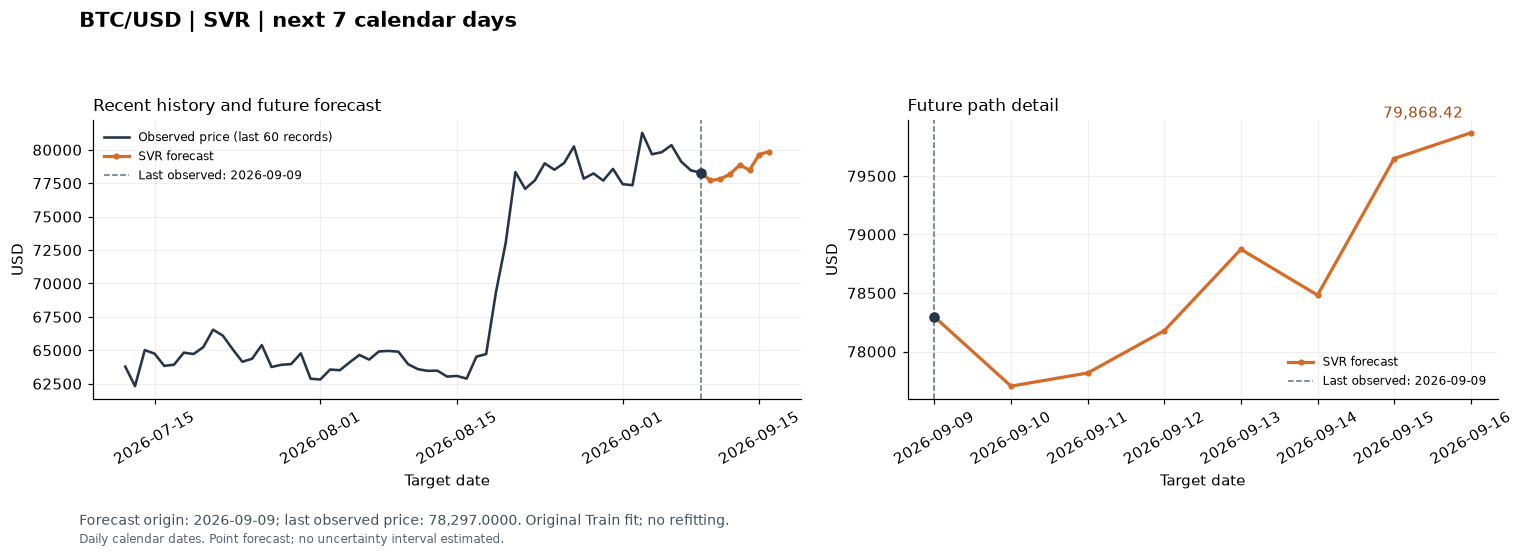

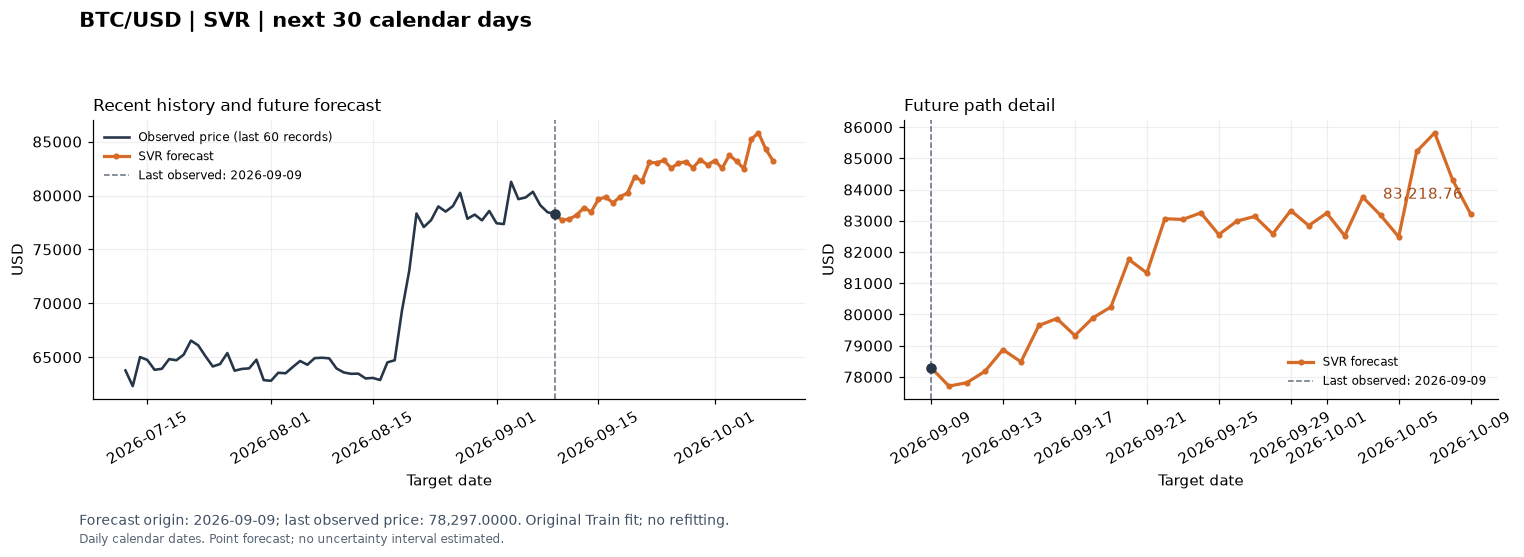

In [15]:
# Plot the already computed future path; no fitting or new inference.
FUTURE_MODEL_LABEL = 'SVR'
FUTURE_UNCERTAINTY_NOTE = 'Point forecast; no uncertainty interval estimated.'
FUTURE_PLOT_LABEL = 'BTC/USD'
FUTURE_PLOT_UNIT = 'USD'
FUTURE_STEP_LABEL = 'calendar days'
FUTURE_DATE_NOTE = 'Daily calendar dates.'

def plot_model_future_path(history, future_path, steps):
    path = future_path.sort_values('h').iloc[:steps].copy()
    origin = pd.Timestamp(history.index[-1])
    last_actual = float(history.iloc[-1])
    forecast_column = next(c for c in ['svr_fc', 'xgb_fc', 'patchtst_fc_ens', 'forecast'] if c in path)
    seed_columns = [column for column in path if column.startswith(('patchtst_fc_seed', 'forecast_seed'))]
    dates = pd.DatetimeIndex(pd.to_datetime(path['target_date']))
    values = path[forecast_column].to_numpy(dtype=float)
    assert len(path) == steps and path['h'].tolist() == list(range(1, steps + 1))
    assert dates.is_unique and dates.is_monotonic_increasing and (dates > origin).all()
    assert (pd.to_datetime(path['origin_date']) == origin).all()
    assert np.isfinite(values).all() and (values > 0).all()
    np.testing.assert_allclose(path['price_origin'], last_actual, rtol=1e-12)

    joined_dates = pd.DatetimeIndex([origin, *dates])
    joined_forecast = np.r_[last_actual, values]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1.2, 1]})
    recent = history.iloc[-60:]
    axes[0].plot(recent.index, recent, color='#263648', linewidth=1.7, label='Observed price (last 60 records)')
    for ax in axes:
        ax.plot(joined_dates, joined_forecast, color='#d56b27', linewidth=2.1,
                marker='o', markersize=3, label=f'{FUTURE_MODEL_LABEL} forecast')
        ax.axvline(origin, color='#627080', linestyle='--', linewidth=1,
                   label=f'Last observed: {origin:%Y-%m-%d}')
        ax.scatter([origin], [last_actual], color='#263648', s=35, zorder=4)
        if seed_columns:
            seed_values = path[seed_columns].to_numpy(dtype=float)
            assert np.isfinite(seed_values).all() and (seed_values > 0).all()
            low = np.r_[last_actual, seed_values.min(axis=1)]
            high = np.r_[last_actual, seed_values.max(axis=1)]
            ax.fill_between(joined_dates, low, high, color='#d56b27', alpha=.13,
                            label=f'Range across {len(seed_columns)} seeds')
        if {'xgb_lo95', 'xgb_hi95'}.issubset(path.columns):
            interval = path[['xgb_lo95', 'xgb_hi95']].to_numpy(dtype=float)
            assert np.isfinite(interval).all() and (interval > 0).all()
            assert (interval[:, 0] <= interval[:, 1]).all()
            ax.fill_between(joined_dates, np.r_[last_actual, interval[:, 0]],
                            np.r_[last_actual, interval[:, 1]], color='#d56b27', alpha=.13,
                            label='Nominal 95% quantile prediction interval')
        ax.set(ylabel=FUTURE_PLOT_UNIT, xlabel='Target date')
        ax.grid(alpha=.2)
        ax.spines[['top', 'right']].set_visible(False)
        ax.tick_params(axis='x', labelrotation=30)
    axes[0].set_title('Recent history and future forecast', loc='left', fontsize=11)
    axes[1].set_title('Future path detail', loc='left', fontsize=11)
    endpoint_label = f'{values[-1]:,.6f}' if FUTURE_PLOT_LABEL == 'USD/EUR' else f'{values[-1]:,.2f}'
    axes[1].annotate(endpoint_label, xy=(dates[-1], values[-1]),
                     xytext=(-5, 10), textcoords='offset points', ha='right', color='#a34a15')
    axes[0].legend(loc='best', fontsize=8, frameon=False)
    axes[1].legend(loc='best', fontsize=8, frameon=False)
    fig.suptitle(f'{FUTURE_PLOT_LABEL} | {FUTURE_MODEL_LABEL} | next {steps} {FUTURE_STEP_LABEL}',
                 fontsize=14, fontweight='bold', x=.055, ha='left')
    fig.text(.055, .045, f'Forecast origin: {origin:%Y-%m-%d}; last observed price: {last_actual:,.4f}. '
             'Original Train fit; no refitting.', fontsize=9, color='#405164')
    fig.text(.055, .012, FUTURE_DATE_NOTE + ' ' + FUTURE_UNCERTAINTY_NOTE,
             fontsize=8, color='#596574')
    fig.tight_layout(rect=(0, .08, 1, .92))
    return fig

for future_steps in [7, 30]:
    future_fig = plot_model_future_path(df['Price'], future_forecast_daily, future_steps)
    plt.show()
    plt.close(future_fig)

<a id="task1-future-metrics"></a>

### 9.5 — Task 1: Original archived future forecast RMSE/MAPE

**Source:** original saved forecasts from **9 September 2026**, evaluated against `Bitcoin Historical Data (2).csv` in `ACTUAL_FOR_PREDICT`. Match by the original target dates; no retraining, calendar changes, date shifting or price imputation. These future forecasts have now been observed; this evaluation is separate from the historical Test set.

The tables show (A) actual/forecast pairs, (B) requested horizons, and (C) whole 7/30-step paths. **One origin gives n=1 per horizon**, so per-horizon RMSE is absolute error and MAPE is the single percentage error. Path metrics combine different horizons from that origin; they are not rolling-origin Test scores. Missing dates stay N/A and partial-window counts are explicit.

**Units:** RMSE in USD; MAPE in percent. **Forecast precision:** full precision saved forecast CSV; checked against saved notebook output. LSTM/Transformer use the original predefined-seed ensemble forecast, not an average of seed metrics. Archive values are embedded in the next cell and cannot be overwritten by later inference.

[Go to Task 2 — Test set](#task2-test-metrics)


In [16]:
# Evaluate an immutable archive of the original forecasts, without fitting any model.
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, HTML

task1_model = 'SVR'
task1_asset = 'BTC'
task1_unit = 'USD'
task1_horizons = [1, 3, 5, 7, 14, 21, 30]
task1_archive_provenance = {'source': 'OUTPUT\\outputs_svr\\tables\\future_forecast_daily_30d.csv', 'precision': 'full precision saved forecast CSV; checked against saved notebook output', 'original_notebook_sha256': 'cae1e5d9100ac82c707c187fb4c8faa48304e909822319bb17f232f86a2d8619', 'original_data_source': 'CSV/Bitcoin Historical Data.csv', 'original_data_sha256': '26ac572d5c806c7d2be814fa93c3b0de970786a01e8d813998292f104d9fcc15'}
task1_archive = pd.DataFrame(json.loads('[{"origin_date": "2026-09-09", "h": 1, "target_date": "2026-09-10", "Forecast": 77862.715479629}, {"origin_date": "2026-09-09", "h": 2, "target_date": "2026-09-11", "Forecast": 77764.43865853833}, {"origin_date": "2026-09-09", "h": 3, "target_date": "2026-09-12", "Forecast": 77873.38939771998}, {"origin_date": "2026-09-09", "h": 4, "target_date": "2026-09-13", "Forecast": 78999.07842303917}, {"origin_date": "2026-09-09", "h": 5, "target_date": "2026-09-14", "Forecast": 78950.8719176473}, {"origin_date": "2026-09-09", "h": 6, "target_date": "2026-09-15", "Forecast": 80350.43235649736}, {"origin_date": "2026-09-09", "h": 7, "target_date": "2026-09-16", "Forecast": 80457.30195190663}, {"origin_date": "2026-09-09", "h": 8, "target_date": "2026-09-17", "Forecast": 79893.67687143522}, {"origin_date": "2026-09-09", "h": 9, "target_date": "2026-09-18", "Forecast": 79712.44316172434}, {"origin_date": "2026-09-09", "h": 10, "target_date": "2026-09-19", "Forecast": 79726.69018921646}, {"origin_date": "2026-09-09", "h": 11, "target_date": "2026-09-20", "Forecast": 81919.64966181928}, {"origin_date": "2026-09-09", "h": 12, "target_date": "2026-09-21", "Forecast": 81542.3140803462}, {"origin_date": "2026-09-09", "h": 13, "target_date": "2026-09-22", "Forecast": 82815.35763937217}, {"origin_date": "2026-09-09", "h": 14, "target_date": "2026-09-23", "Forecast": 82674.94563835165}, {"origin_date": "2026-09-09", "h": 15, "target_date": "2026-09-24", "Forecast": 82890.96925243127}, {"origin_date": "2026-09-09", "h": 16, "target_date": "2026-09-25", "Forecast": 83589.92218084024}, {"origin_date": "2026-09-09", "h": 17, "target_date": "2026-09-26", "Forecast": 83386.69862667599}, {"origin_date": "2026-09-09", "h": 18, "target_date": "2026-09-27", "Forecast": 82758.33412098353}, {"origin_date": "2026-09-09", "h": 19, "target_date": "2026-09-28", "Forecast": 82792.91483356756}, {"origin_date": "2026-09-09", "h": 20, "target_date": "2026-09-29", "Forecast": 84151.98961021205}, {"origin_date": "2026-09-09", "h": 21, "target_date": "2026-09-30", "Forecast": 83736.52522787233}, {"origin_date": "2026-09-09", "h": 22, "target_date": "2026-10-01", "Forecast": 84294.24953765707}, {"origin_date": "2026-09-09", "h": 23, "target_date": "2026-10-02", "Forecast": 83038.38843998661}, {"origin_date": "2026-09-09", "h": 24, "target_date": "2026-10-03", "Forecast": 83914.70149470725}, {"origin_date": "2026-09-09", "h": 25, "target_date": "2026-10-04", "Forecast": 82854.54046554789}, {"origin_date": "2026-09-09", "h": 26, "target_date": "2026-10-05", "Forecast": 84108.89095464474}, {"origin_date": "2026-09-09", "h": 27, "target_date": "2026-10-06", "Forecast": 84986.02607993124}, {"origin_date": "2026-09-09", "h": 28, "target_date": "2026-10-07", "Forecast": 84493.53930851976}, {"origin_date": "2026-09-09", "h": 29, "target_date": "2026-10-08", "Forecast": 83258.42608190345}, {"origin_date": "2026-09-09", "h": 30, "target_date": "2026-10-09", "Forecast": 82519.65584423479}]'))
task1_root = next(base for base in [Path.cwd(), *Path.cwd().parents]
    if (base / 'ACTUAL_FOR_PREDICT').is_dir() and (base / 'CSV').is_dir())
task1_actual_path = task1_root / 'ACTUAL_FOR_PREDICT' / 'Bitcoin Historical Data (2).csv'
task1_actual = pd.read_csv(task1_actual_path, encoding='utf-8-sig')
task1_actual['target_date'] = pd.to_datetime(task1_actual['Date'], format='%m/%d/%Y', errors='raise')
task1_actual['Actual'] = pd.to_numeric(task1_actual['Price'].astype(str).str.replace(',', '', regex=False), errors='raise')
assert task1_actual['target_date'].notna().all() and not task1_actual['target_date'].duplicated().any()
assert np.isfinite(task1_actual['Actual']).all() and task1_actual['Actual'].gt(0).all()
for task1_column in ['origin_date', 'target_date']:
    task1_archive[task1_column] = pd.to_datetime(task1_archive[task1_column], errors='raise')
assert task1_archive['h'].tolist() == list(range(1, 31))
assert task1_archive['origin_date'].nunique() == 1 and task1_archive['target_date'].is_unique
assert task1_archive['target_date'].is_monotonic_increasing
assert (task1_archive['target_date'] > task1_archive['origin_date']).all()
assert np.isfinite(task1_archive['Forecast']).all() and task1_archive['Forecast'].gt(0).all()

task1_comparison = task1_archive.merge(task1_actual[['target_date', 'Actual']],
    on='target_date', how='left', validate='one_to_one')
np.testing.assert_array_equal(task1_comparison['Forecast'], task1_archive['Forecast'])
assert len(task1_comparison) == 30
task1_comparison['Error'] = task1_comparison['Forecast'] - task1_comparison['Actual']
task1_comparison['APE (%)'] = 100 * task1_comparison['Error'].abs() / task1_comparison['Actual']
task1_comparison['Status'] = np.where(task1_comparison['Actual'].notna(),
    'Matched original target date', 'Missing actual: original target date retained')
task1_horizon_metrics = task1_comparison.loc[task1_comparison.h.isin(task1_horizons),
    ['origin_date', 'h', 'target_date', 'Forecast', 'Actual']].copy()
task1_horizon_metrics['n_actuals'] = task1_horizon_metrics['Actual'].notna().astype(int)
task1_horizon_metrics['RMSE'] = (task1_horizon_metrics['Forecast'] - task1_horizon_metrics['Actual']).abs()
task1_horizon_metrics['RMSE_unit'] = task1_unit
task1_horizon_metrics['MAPE (%)'] = 100 * task1_horizon_metrics['RMSE'] / task1_horizon_metrics['Actual']
task1_window_rows = []
for task1_window in [7, 30]:
    task1_part = task1_comparison.loc[task1_comparison.h.le(task1_window)]
    task1_matched = task1_part.dropna(subset=['Actual'])
    task1_error = task1_matched['Forecast'].to_numpy() - task1_matched['Actual'].to_numpy()
    task1_window_rows.append(dict(window_steps=task1_window, n_expected=len(task1_part),
        n_actuals=len(task1_matched), n_missing=len(task1_part)-len(task1_matched),
        first_target_date=task1_part.target_date.min(), last_target_date=task1_part.target_date.max(),
        RMSE=float(np.sqrt(np.mean(task1_error**2))) if len(task1_matched) else np.nan,
        RMSE_unit=task1_unit,
        MAPE_percent=float(100*np.mean(np.abs(task1_error/task1_matched['Actual'].to_numpy()))) if len(task1_matched) else np.nan,
        Status='Complete' if len(task1_part)==len(task1_matched) else 'Partial: matched dates only'))
task1_window_metrics = pd.DataFrame(task1_window_rows).rename(columns={'MAPE_percent': 'MAPE (%)'})
task1_missing = task1_comparison.loc[task1_comparison.Actual.isna(), ['h', 'target_date']].copy()

def task1_show_table(frame):
    shown = frame.copy()
    for column in ['origin_date', 'target_date', 'first_target_date', 'last_target_date']:
        if column in shown:
            shown[column] = pd.to_datetime(shown[column]).dt.strftime('%Y-%m-%d')
    display(HTML('<div style="max-height:420px;overflow:auto;border:1px solid #ddd;padding:8px">'
        + shown.to_html(index=False, na_rep='N/A', float_format=lambda value: f'{value:,.6f}') + '</div>'))

display(Markdown('**Task 1A — Original future forecast / actual pairs (prices in ' + task1_unit + ')**'))
task1_show_table(task1_comparison)
display(Markdown('**Task 1B — Future RMSE/MAPE by horizon; one original origin, n=1 per horizon**'))
task1_show_table(task1_horizon_metrics)
display(Markdown('**Task 1C — RMSE/MAPE across each plotted 7/30-step future path (mixed horizons)**'))
task1_show_table(task1_window_metrics)
if not task1_missing.empty:
    display(Markdown('**Missing actual prices: no date shifting or imputation**'))
    task1_show_table(task1_missing)
task1_output = task1_root / 'OUTPUT' / 'METRICS_REVIEW' / 'Task1_Future' / 'SVR_BTC'
task1_output.mkdir(parents=True, exist_ok=True)
for task1_name, task1_frame in [('original_forecast_archive.csv', task1_archive),
        ('forecast_actual_pairs.csv', task1_comparison), ('metrics_by_horizon.csv', task1_horizon_metrics),
        ('metrics_7_30_steps.csv', task1_window_metrics), ('missing_actual_dates.csv', task1_missing)]:
    task1_frame.to_csv(task1_output / task1_name, index=False, encoding='utf-8-sig')
task1_provenance = dict(task1_archive_provenance, actual_source=str(task1_actual_path.relative_to(task1_root)),
    actual_sha256=hashlib.sha256(task1_actual_path.read_bytes()).hexdigest(),
    model=task1_model, asset=task1_asset, origin=str(task1_archive.origin_date.iloc[0].date()),
    forecast_sha256=hashlib.sha256(task1_archive.to_csv(index=False).encode('utf-8')).hexdigest(),
    matching='exact original target date; no imputation or date shifts', refit_for_evaluation=False)
(task1_output / 'provenance.json').write_text(json.dumps(task1_provenance, indent=2, ensure_ascii=False), encoding='utf-8')
print('Forecast source:', task1_archive_provenance['source'])
print('Actual prices:', task1_actual_path.name, '| forecast origin:', task1_archive.origin_date.iloc[0].date())
print('Per-horizon n=1: RMSE equals absolute error; MAPE is the single absolute percentage error.')
print('Window metrics mix horizons from one origin and are separate from Test-set performance.')
print('CSV results:', task1_output)

**Task 1A — Original future forecast / actual pairs (prices in USD)**

origin_date,h,target_date,Forecast,Actual,Error,APE (%),Status
2026-09-09,1,2026-09-10,"77,862.715480","76,565.100000","1,297.615480",1.694787,Matched original target date
2026-09-09,2,2026-09-11,"77,764.438659","77,220.500000",543.938659,0.704397,Matched original target date
2026-09-09,3,2026-09-12,"77,873.389398","77,282.400000",590.989398,0.764714,Matched original target date
2026-09-09,4,2026-09-13,"78,999.078423","76,843.500000","2,155.578423",2.805154,Matched original target date
2026-09-09,5,2026-09-14,"78,950.871918","78,185.300000",765.571918,0.979176,Matched original target date
2026-09-09,6,2026-09-15,"80,350.432356","75,620.400000","4,730.032356",6.254969,Matched original target date
2026-09-09,7,2026-09-16,"80,457.301952","76,191.400000","4,265.901952",5.598928,Matched original target date
2026-09-09,8,2026-09-17,"79,893.676871","76,439.900000","3,453.776871",4.518291,Matched original target date
2026-09-09,9,2026-09-18,"79,712.443162","80,882.000000","-1,169.556838",1.446004,Matched original target date
2026-09-09,10,2026-09-19,"79,726.690189","81,253.100000","-1,526.409811",1.878587,Matched original target date


**Task 1B — Future RMSE/MAPE by horizon; one original origin, n=1 per horizon**

origin_date,h,target_date,Forecast,Actual,n_actuals,RMSE,RMSE_unit,MAPE (%)
2026-09-09,1,2026-09-10,"77,862.715480","76,565.100000",1,"1,297.615480",USD,1.694787
2026-09-09,3,2026-09-12,"77,873.389398","77,282.400000",1,590.989398,USD,0.764714
2026-09-09,5,2026-09-14,"78,950.871918","78,185.300000",1,765.571918,USD,0.979176
2026-09-09,7,2026-09-16,"80,457.301952","76,191.400000",1,"4,265.901952",USD,5.598928
2026-09-09,14,2026-09-23,"82,674.945638","84,394.400000",1,"1,719.454362",USD,2.037403
2026-09-09,21,2026-09-30,"83,736.525228","83,612.200000",1,124.325228,USD,0.148693
2026-09-09,30,2026-10-09,"82,519.655844","82,623.600000",1,103.944156,USD,0.125804


**Task 1C — RMSE/MAPE across each plotted 7/30-step future path (mixed horizons)**

window_steps,n_expected,n_actuals,n_missing,first_target_date,last_target_date,RMSE,RMSE_unit,MAPE (%),Status
7,7,7,0,2026-09-10,2026-09-16,"2,622.231545",USD,2.686018,Complete
30,30,30,0,2026-09-10,2026-10-09,"2,124.622938",USD,2.011013,Complete


Forecast source: OUTPUT\outputs_svr\tables\future_forecast_daily_30d.csv
Actual prices: Bitcoin Historical Data (2).csv | forecast origin: 2026-09-09
Per-horizon n=1: RMSE equals absolute error; MAPE is the single absolute percentage error.
Window metrics mix horizons from one origin and are separate from Test-set performance.
CSV results: C:\Users\User\Desktop\PROJECT_2026\OUTPUT\METRICS_REVIEW\Task1_Future\SVR_BTC


<a id="svr-revised-future"></a>

### 9.6 — Revised future RMSE/MAPE after Train-only Top 5 search

Evaluate the **new rank-1 Train-selected models** from this run against the supplied actual prices. Original archived-forecast metrics remain in the preceding section. This is retrospective evaluation on dates already inspected, not forecasts issued before those actual prices were known. Candidate ranking and model fitting exclude Test and these future actual prices. Missing original target dates remain N/A.


In [17]:
# Evaluate an immutable archive of the original forecasts, without fitting any model.
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, HTML

svr_revised_model = 'SVR'
svr_revised_asset = 'BTC'
svr_revised_unit = 'USD'
svr_revised_horizons = [1, 3, 5, 7, 14, 21, 30]
svr_revised_archive_provenance = dict(source='Current Train-ranked SVR execution; full precision', precision='full precision; retrospective rerun after actual dates were inspected')
svr_revised_archive = future_forecast_daily[['origin_date', 'h', 'target_date', 'svr_fc']].copy().rename(columns={'svr_fc': 'Forecast'})
svr_revised_root = next(base for base in [Path.cwd(), *Path.cwd().parents]
    if (base / 'ACTUAL_FOR_PREDICT').is_dir() and (base / 'CSV').is_dir())
svr_revised_actual_path = svr_revised_root / 'ACTUAL_FOR_PREDICT' / 'Bitcoin Historical Data (2).csv'
svr_revised_actual = pd.read_csv(svr_revised_actual_path, encoding='utf-8-sig')
svr_revised_actual['target_date'] = pd.to_datetime(svr_revised_actual['Date'], format='%m/%d/%Y', errors='raise')
svr_revised_actual['Actual'] = pd.to_numeric(svr_revised_actual['Price'].astype(str).str.replace(',', '', regex=False), errors='raise')
assert svr_revised_actual['target_date'].notna().all() and not svr_revised_actual['target_date'].duplicated().any()
assert np.isfinite(svr_revised_actual['Actual']).all() and svr_revised_actual['Actual'].gt(0).all()
for svr_revised_column in ['origin_date', 'target_date']:
    svr_revised_archive[svr_revised_column] = pd.to_datetime(svr_revised_archive[svr_revised_column], errors='raise')
assert svr_revised_archive['h'].tolist() == list(range(1, 31))
assert svr_revised_archive['origin_date'].nunique() == 1 and svr_revised_archive['target_date'].is_unique
assert svr_revised_archive['target_date'].is_monotonic_increasing
assert (svr_revised_archive['target_date'] > svr_revised_archive['origin_date']).all()
assert np.isfinite(svr_revised_archive['Forecast']).all() and svr_revised_archive['Forecast'].gt(0).all()

svr_revised_comparison = svr_revised_archive.merge(svr_revised_actual[['target_date', 'Actual']],
    on='target_date', how='left', validate='one_to_one')
np.testing.assert_array_equal(svr_revised_comparison['Forecast'], svr_revised_archive['Forecast'])
assert len(svr_revised_comparison) == 30
svr_revised_comparison['Error'] = svr_revised_comparison['Forecast'] - svr_revised_comparison['Actual']
svr_revised_comparison['APE (%)'] = 100 * svr_revised_comparison['Error'].abs() / svr_revised_comparison['Actual']
svr_revised_comparison['Status'] = np.where(svr_revised_comparison['Actual'].notna(),
    'Matched original target date', 'Missing actual: original target date retained')
svr_revised_horizon_metrics = svr_revised_comparison.loc[svr_revised_comparison.h.isin(svr_revised_horizons),
    ['origin_date', 'h', 'target_date', 'Forecast', 'Actual']].copy()
svr_revised_horizon_metrics['n_actuals'] = svr_revised_horizon_metrics['Actual'].notna().astype(int)
svr_revised_horizon_metrics['RMSE'] = (svr_revised_horizon_metrics['Forecast'] - svr_revised_horizon_metrics['Actual']).abs()
svr_revised_horizon_metrics['RMSE_unit'] = svr_revised_unit
svr_revised_horizon_metrics['MAPE (%)'] = 100 * svr_revised_horizon_metrics['RMSE'] / svr_revised_horizon_metrics['Actual']
svr_revised_window_rows = []
for svr_revised_window in [7, 30]:
    svr_revised_part = svr_revised_comparison.loc[svr_revised_comparison.h.le(svr_revised_window)]
    svr_revised_matched = svr_revised_part.dropna(subset=['Actual'])
    svr_revised_error = svr_revised_matched['Forecast'].to_numpy() - svr_revised_matched['Actual'].to_numpy()
    svr_revised_window_rows.append(dict(window_steps=svr_revised_window, n_expected=len(svr_revised_part),
        n_actuals=len(svr_revised_matched), n_missing=len(svr_revised_part)-len(svr_revised_matched),
        first_target_date=svr_revised_part.target_date.min(), last_target_date=svr_revised_part.target_date.max(),
        RMSE=float(np.sqrt(np.mean(svr_revised_error**2))) if len(svr_revised_matched) else np.nan,
        RMSE_unit=svr_revised_unit,
        MAPE_percent=float(100*np.mean(np.abs(svr_revised_error/svr_revised_matched['Actual'].to_numpy()))) if len(svr_revised_matched) else np.nan,
        Status='Complete' if len(svr_revised_part)==len(svr_revised_matched) else 'Partial: matched dates only'))
svr_revised_window_metrics = pd.DataFrame(svr_revised_window_rows).rename(columns={'MAPE_percent': 'MAPE (%)'})
svr_revised_missing = svr_revised_comparison.loc[svr_revised_comparison.Actual.isna(), ['h', 'target_date']].copy()

def svr_revised_show_table(frame):
    shown = frame.copy()
    for column in ['origin_date', 'target_date', 'first_target_date', 'last_target_date']:
        if column in shown:
            shown[column] = pd.to_datetime(shown[column]).dt.strftime('%Y-%m-%d')
    display(HTML('<div style="max-height:420px;overflow:auto;border:1px solid #ddd;padding:8px">'
        + shown.to_html(index=False, na_rep='N/A', float_format=lambda value: f'{value:,.6f}') + '</div>'))

display(Markdown('**Task 1A — Revised Train-ranked future forecast / actual pairs (prices in ' + svr_revised_unit + ')**'))
svr_revised_show_table(svr_revised_comparison)
display(Markdown('**Task 1B — Future RMSE/MAPE by horizon; one original origin, n=1 per horizon**'))
svr_revised_show_table(svr_revised_horizon_metrics)
display(Markdown('**Task 1C — RMSE/MAPE across each plotted 7/30-step future path (mixed horizons)**'))
svr_revised_show_table(svr_revised_window_metrics)
if not svr_revised_missing.empty:
    display(Markdown('**Missing actual prices: no date shifting or imputation**'))
    svr_revised_show_table(svr_revised_missing)
svr_revised_output = svr_revised_root / 'OUTPUT' / 'METRICS_REVIEW' / 'Task1_Future_Revised_TrainSearch' / 'SVR_BTC'
svr_revised_output.mkdir(parents=True, exist_ok=True)
for svr_revised_name, svr_revised_frame in [('revised_forecast_snapshot.csv', svr_revised_archive),
        ('forecast_actual_pairs.csv', svr_revised_comparison), ('metrics_by_horizon.csv', svr_revised_horizon_metrics),
        ('metrics_7_30_steps.csv', svr_revised_window_metrics), ('missing_actual_dates.csv', svr_revised_missing)]:
    svr_revised_frame.to_csv(svr_revised_output / svr_revised_name, index=False, encoding='utf-8-sig')
svr_revised_provenance = dict(svr_revised_archive_provenance, actual_source=str(svr_revised_actual_path.relative_to(svr_revised_root)),
    actual_sha256=hashlib.sha256(svr_revised_actual_path.read_bytes()).hexdigest(),
    model=svr_revised_model, asset=svr_revised_asset, origin=str(svr_revised_archive.origin_date.iloc[0].date()),
    forecast_sha256=hashlib.sha256(svr_revised_archive.to_csv(index=False).encode('utf-8')).hexdigest(),
    matching='exact original target date; no imputation or date shifts', refit_for_evaluation=False)
(svr_revised_output / 'provenance.json').write_text(json.dumps(svr_revised_provenance, indent=2, ensure_ascii=False), encoding='utf-8')
print('Forecast source:', svr_revised_archive_provenance['source'])
print('Actual prices:', svr_revised_actual_path.name, '| forecast origin:', svr_revised_archive.origin_date.iloc[0].date())
print('Per-horizon n=1: RMSE equals absolute error; MAPE is the single absolute percentage error.')
print('Window metrics mix horizons from one origin and are separate from Test-set performance.')
print('CSV results:', svr_revised_output)

print('RETROSPECTIVE RERUN: these actual-price dates were already inspected; parameters were selected using Train only.')


**Task 1A — Revised Train-ranked future forecast / actual pairs (prices in USD)**

origin_date,h,target_date,Forecast,Actual,Error,APE (%),Status
2026-09-09,1,2026-09-10,"77,704.583254","76,565.100000","1,139.483254",1.488254,Matched original target date
2026-09-09,2,2026-09-11,"77,816.593663","77,220.500000",596.093663,0.771937,Matched original target date
2026-09-09,3,2026-09-12,"78,177.784513","77,282.400000",895.384513,1.158588,Matched original target date
2026-09-09,4,2026-09-13,"78,873.586722","76,843.500000","2,030.086722",2.641846,Matched original target date
2026-09-09,5,2026-09-14,"78,481.901340","78,185.300000",296.601340,0.379357,Matched original target date
2026-09-09,6,2026-09-15,"79,648.683193","75,620.400000","4,028.283193",5.326979,Matched original target date
2026-09-09,7,2026-09-16,"79,868.420406","76,191.400000","3,677.020406",4.826031,Matched original target date
2026-09-09,8,2026-09-17,"79,323.522918","76,439.900000","2,883.622918",3.772405,Matched original target date
2026-09-09,9,2026-09-18,"79,890.575699","80,882.000000",-991.424301,1.225766,Matched original target date
2026-09-09,10,2026-09-19,"80,239.058372","81,253.100000","-1,014.041628",1.248004,Matched original target date


**Task 1B — Future RMSE/MAPE by horizon; one original origin, n=1 per horizon**

origin_date,h,target_date,Forecast,Actual,n_actuals,RMSE,RMSE_unit,MAPE (%)
2026-09-09,1,2026-09-10,"77,704.583254","76,565.100000",1,"1,139.483254",USD,1.488254
2026-09-09,3,2026-09-12,"78,177.784513","77,282.400000",1,895.384513,USD,1.158588
2026-09-09,5,2026-09-14,"78,481.901340","78,185.300000",1,296.601340,USD,0.379357
2026-09-09,7,2026-09-16,"79,868.420406","76,191.400000",1,"3,677.020406",USD,4.826031
2026-09-09,14,2026-09-23,"83,043.839915","84,394.400000",1,"1,350.560085",USD,1.600296
2026-09-09,21,2026-09-30,"82,846.362949","83,612.200000",1,765.837051,USD,0.915939
2026-09-09,30,2026-10-09,"83,218.758756","82,623.600000",1,595.158756,USD,0.720325


**Task 1C — RMSE/MAPE across each plotted 7/30-step future path (mixed horizons)**

window_steps,n_expected,n_actuals,n_missing,first_target_date,last_target_date,RMSE,RMSE_unit,MAPE (%),Status
7,7,7,0,2026-09-10,2026-09-16,"2,280.733973",USD,2.370427,Complete
30,30,30,0,2026-09-10,2026-10-09,"2,151.498632",USD,2.140773,Complete


Forecast source: Current Train-ranked SVR execution; full precision
Actual prices: Bitcoin Historical Data (2).csv | forecast origin: 2026-09-09
Per-horizon n=1: RMSE equals absolute error; MAPE is the single absolute percentage error.
Window metrics mix horizons from one origin and are separate from Test-set performance.
CSV results: C:\Users\User\Desktop\PROJECT_2026\OUTPUT\METRICS_REVIEW\Task1_Future_Revised_TrainSearch\SVR_BTC
RETROSPECTIVE RERUN: these actual-price dates were already inspected; parameters were selected using Train only.


## Step 10 - RMSE and MAPE Evaluation (SVR Only)
Sanity checks stop and display invalid rows without clipping or retuning. Metrics compare historical test target prices with their aligned forecasts in USD.


In [18]:
for name,frame in [('test',forecasts),('future',future_forecasts)]:
    ratio = frame['svr_fc']/frame['price_origin']
    valid = np.isfinite(frame['svr_fc']) & frame['svr_fc'].gt(0) & ratio.between(0.5,2)
    if not valid.all():
        bad = frame.loc[~valid]
        display(bad)
        save_table(bad,f'forecast_sanity_failures_{name}.csv')
    assert valid.all(), f'Invalid {name} forecasts; stop without clipping or retuning'
def rmse(actual,fc): return float(np.sqrt(np.mean((np.asarray(actual)-np.asarray(fc))**2)))
def mape(actual,fc):
    actual=np.asarray(actual,dtype=float)
    assert (actual>0).all()
    return float(100*np.mean(np.abs((actual-np.asarray(fc))/actual)))
evaluation = pd.DataFrame([dict(h=h,n_points=len(group),RMSE=rmse(group['actual'],group['svr_fc']),
    MAPE=mape(group['actual'],group['svr_fc']))
    for h in HORIZONS for group in [forecasts.loc[forecasts['h'].eq(h)]]])
save_table(evaluation,'evaluation_by_horizon.csv')
display(evaluation.style.format({'RMSE':'{:,.2f}','MAPE':'{:.2f}'}).hide(axis='index'))

h,n_points,RMSE,MAPE
1,380,"2,010.94",1.75
3,378,"3,662.68",3.32
5,376,"4,737.94",4.29
7,374,"5,827.10",5.33
14,367,"8,820.22",8.28
21,360,"11,627.14",11.13
30,351,"15,556.48",15.12


<a id="task2-test-metrics"></a>

### Task 2: Test set RMSE/MAPE — Train-ranked SVR rerun

Current execution: each horizon uses its rank-1 parameter set selected solely from Train RMSE. This table is recomputed from the current original chronological Test 20% forecasts, with dates/counts/actual prices checked. The supplied future actuals are excluded. The Test period was inspected in earlier experiments, so this is a retrospective rerun rather than a new independent holdout.

[Top 5 Train parameter sets](#svr-top5-train) · [Original archived future evaluation](#task1-future-metrics)


In [19]:
# Recompute Test-set metrics from the original historical Test forecasts only.
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
from IPython.display import display, HTML

task2_primary_column = 'svr_fc'
task2_unit = 'USD'
task2_model = 'SVR'
task2_asset = 'BTC'
task2_kind = 'model point forecast'
task2_test_pairs = forecasts[['origin_date', 'h', 'target_date', 'actual', task2_primary_column]].copy()
task2_test_pairs = task2_test_pairs.rename(columns={task2_primary_column: 'Forecast'})
for task2_column in ['origin_date', 'target_date']:
    task2_test_pairs[task2_column] = pd.to_datetime(task2_test_pairs[task2_column], errors='raise')
assert n_train == int(0.8 * len(df))
assert task2_test_pairs['target_date'].between(df.index[n_train], df.index[-1]).all()
assert not task2_test_pairs.duplicated(['origin_date', 'h']).any()
assert np.isfinite(task2_test_pairs[['actual', 'Forecast']]).all().all()
task2_target_positions = df.index.get_indexer(task2_test_pairs.target_date)
task2_origin_positions = df.index.get_indexer(task2_test_pairs.origin_date)
assert (task2_origin_positions >= 0).all() and (task2_target_positions >= n_train).all()
assert np.array_equal(task2_target_positions-task2_origin_positions, task2_test_pairs.h.to_numpy())
np.testing.assert_allclose(task2_test_pairs.actual.to_numpy(), df['Price'].iloc[task2_target_positions].to_numpy(), atol=0, rtol=1e-12)
task2_rows = []
for task2_h, task2_group in task2_test_pairs.groupby('h', sort=True):
    assert len(task2_group) == len(df)-n_train-int(task2_h)+1
    task2_actual = task2_group.actual.to_numpy()
    task2_error = task2_group.Forecast.to_numpy()-task2_actual
    task2_zero_count = int((task2_actual == 0).sum())
    task2_rows.append(dict(partition='Test', h=int(task2_h), n_points=len(task2_group),
        first_target_date=task2_group.target_date.min(), last_target_date=task2_group.target_date.max(),
        RMSE=float(np.sqrt(np.mean(task2_error**2))), RMSE_unit=task2_unit,
        MAPE_percent=float(100*np.mean(np.abs(task2_error/task2_actual))) if not task2_zero_count else np.nan,
        zero_actuals=task2_zero_count, forecast_kind=task2_kind))
task2_test_metrics = pd.DataFrame(task2_rows).rename(columns={'MAPE_percent': 'MAPE (%)'})
assert task2_test_metrics.h.tolist() == sorted(HORIZONS)
task2_shown = task2_test_metrics.copy()
for task2_column in ['first_target_date', 'last_target_date']:
    task2_shown[task2_column] = task2_shown[task2_column].dt.strftime('%Y-%m-%d')
display(HTML('<div style="max-height:420px;overflow:auto;border:1px solid #ddd;padding:8px">'
    + task2_shown.to_html(index=False, na_rep='N/A', float_format=lambda value: f'{value:,.6f}') + '</div>'))
task2_root = next(base for base in [Path.cwd(), *Path.cwd().parents]
    if (base / 'ACTUAL_FOR_PREDICT').is_dir() and (base / 'CSV').is_dir())
task2_output = task2_root / 'OUTPUT' / 'METRICS_REVIEW' / 'Task2_Test' / 'SVR_BTC'
task2_output.mkdir(parents=True, exist_ok=True)
task2_test_metrics.to_csv(task2_output / 'metrics_by_horizon.csv', index=False, encoding='utf-8-sig')
task2_test_pairs.to_csv(task2_output / 'test_forecast_pairs.csv', index=False, encoding='utf-8-sig')
print('Partition: original chronological Test 20%; actuals from ACTUAL_FOR_PREDICT are excluded.')
print('Test source:', 'OUTPUT\\outputs_svr\\tables\\forecasts_long.csv (full precision; matched saved notebook tables)')
print('Forecast kind:', task2_kind, '| Units:', task2_unit, '| MAPE: percent')
print('CSV results:', task2_output)

partition,h,n_points,first_target_date,last_target_date,RMSE,RMSE_unit,MAPE (%),zero_actuals,forecast_kind
Test,1,380,2025-08-26,2026-09-09,"2,010.938515",USD,1.750186,0,model point forecast
Test,3,378,2025-08-28,2026-09-09,"3,662.676656",USD,3.319061,0,model point forecast
Test,5,376,2025-08-30,2026-09-09,"4,737.936486",USD,4.286112,0,model point forecast
Test,7,374,2025-09-01,2026-09-09,"5,827.096622",USD,5.329067,0,model point forecast
Test,14,367,2025-09-08,2026-09-09,"8,820.222716",USD,8.275127,0,model point forecast
Test,21,360,2025-09-15,2026-09-09,"11,627.136399",USD,11.126890,0,model point forecast
Test,30,351,2025-09-24,2026-09-09,"15,556.481597",USD,15.120738,0,model point forecast


Partition: original chronological Test 20%; actuals from ACTUAL_FOR_PREDICT are excluded.
Test source: OUTPUT\outputs_svr\tables\forecasts_long.csv (full precision; matched saved notebook tables)
Forecast kind: model point forecast | Units: USD | MAPE: percent
CSV results: C:\Users\User\Desktop\PROJECT_2026\OUTPUT\METRICS_REVIEW\Task2_Test\SVR_BTC


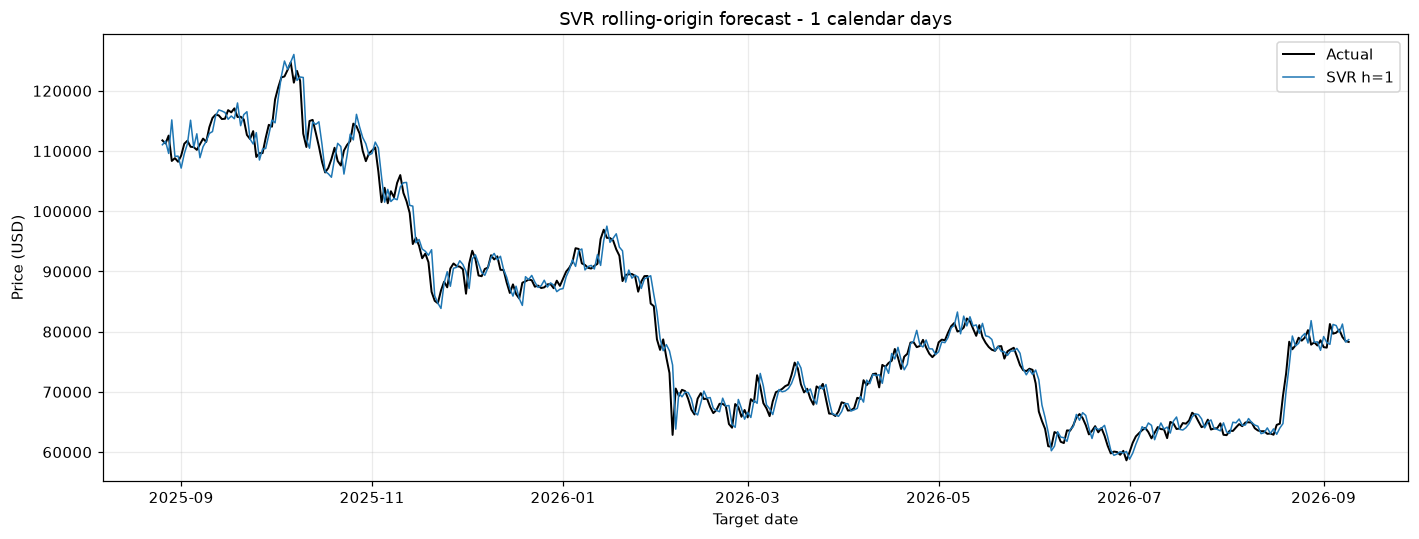

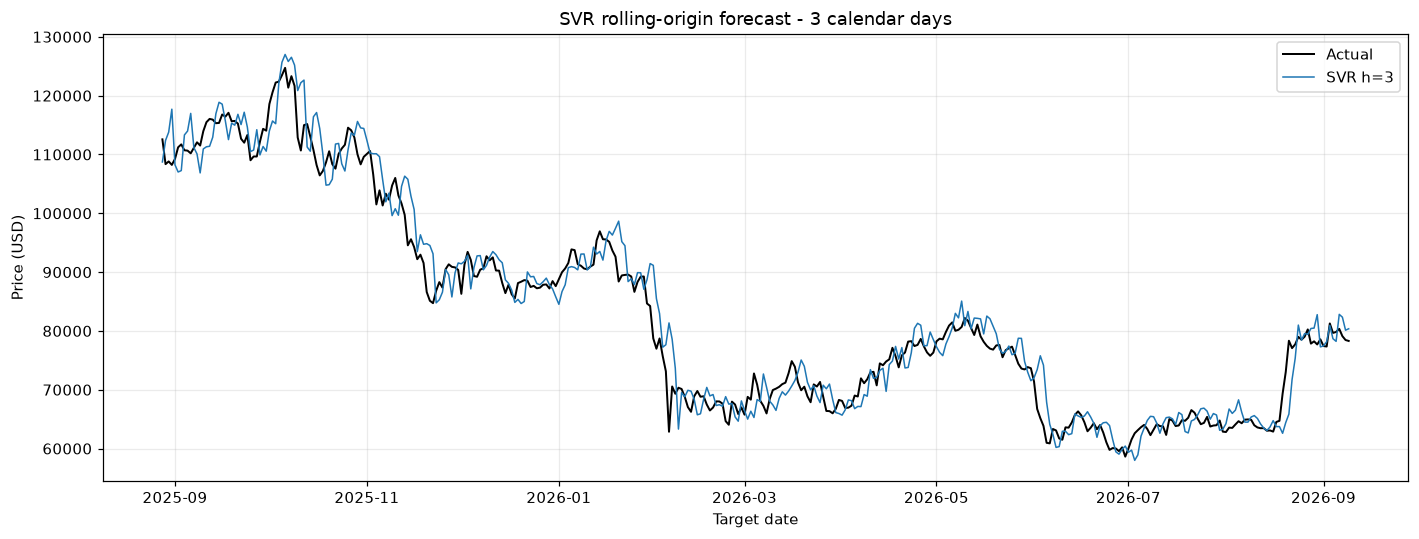

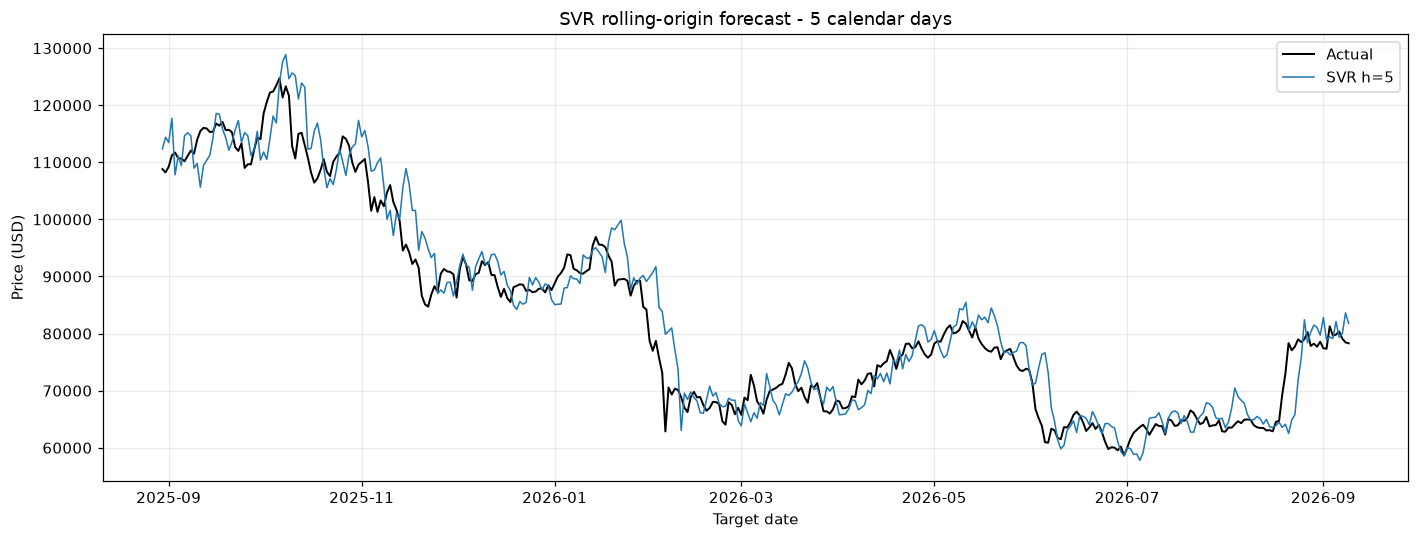

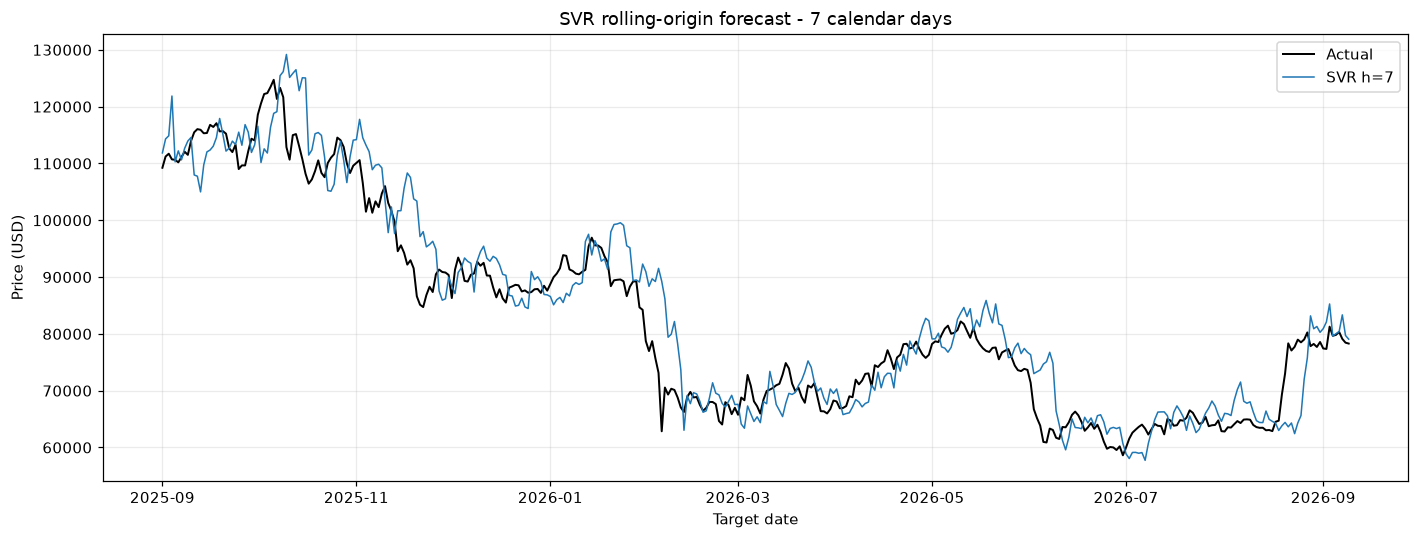

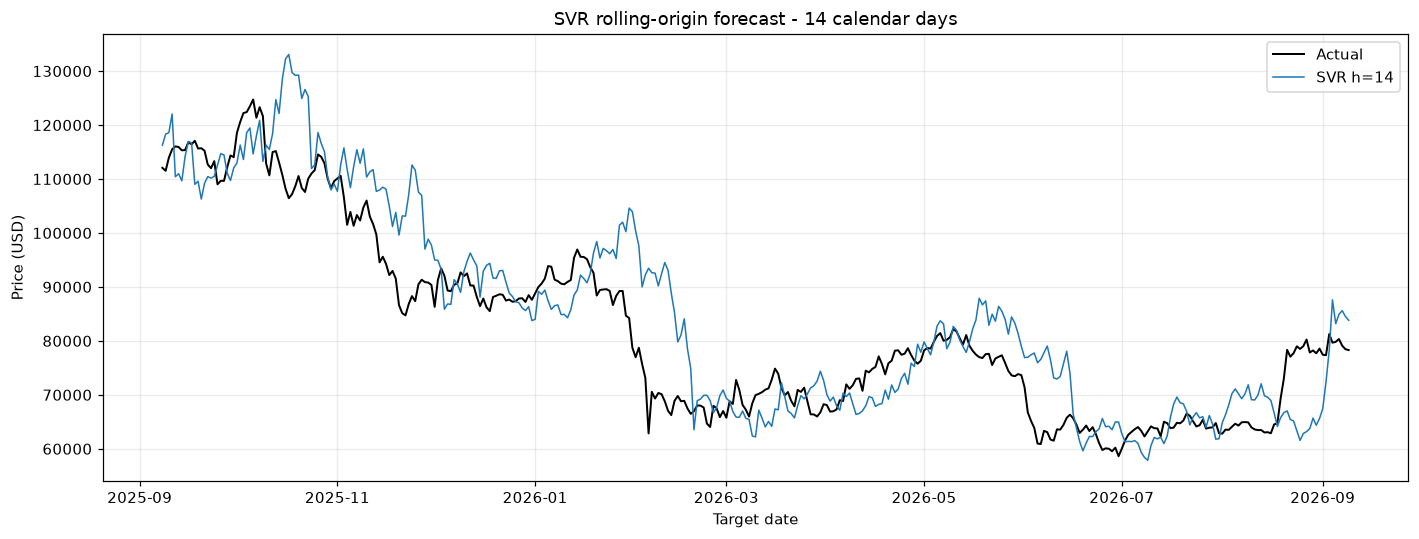

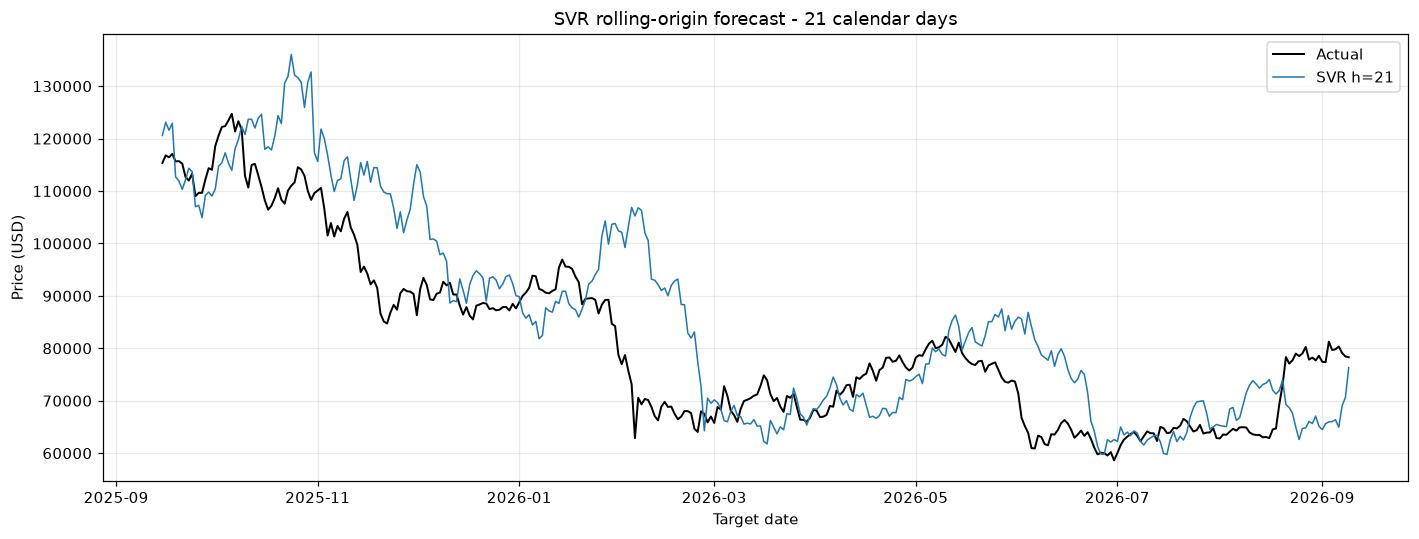

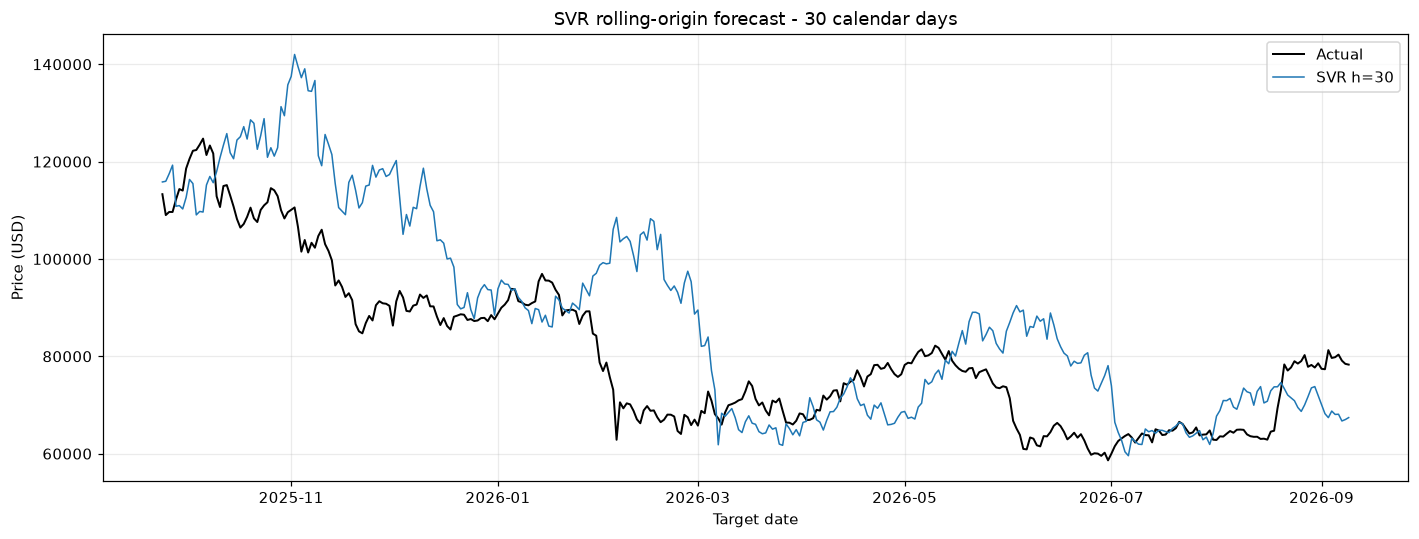

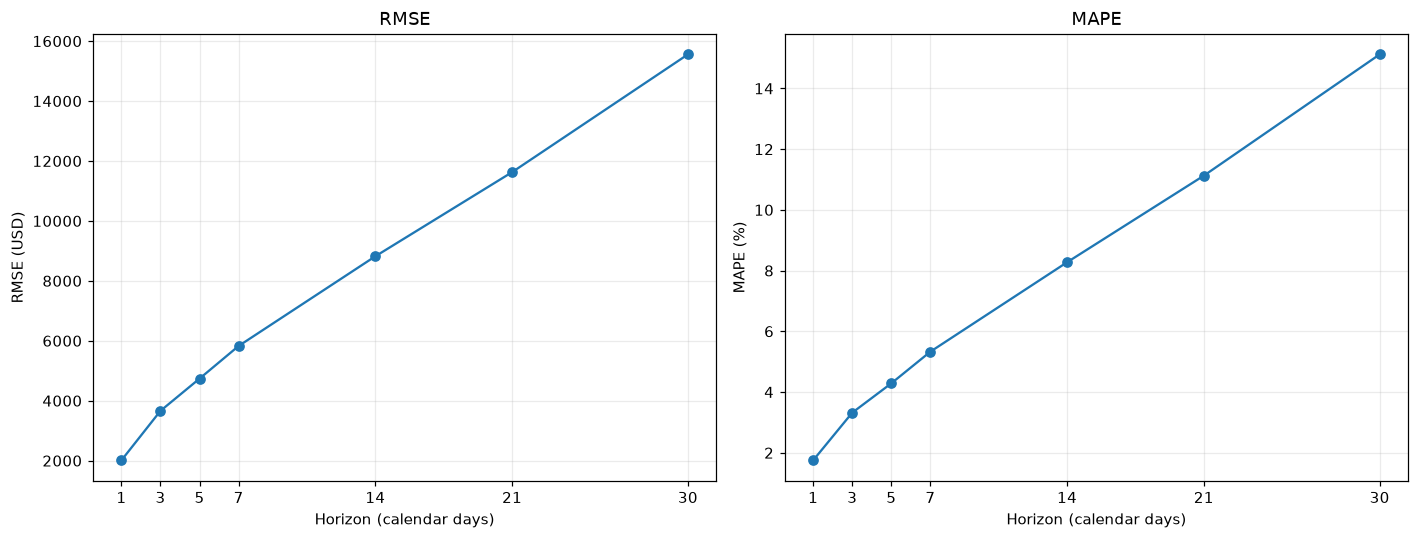

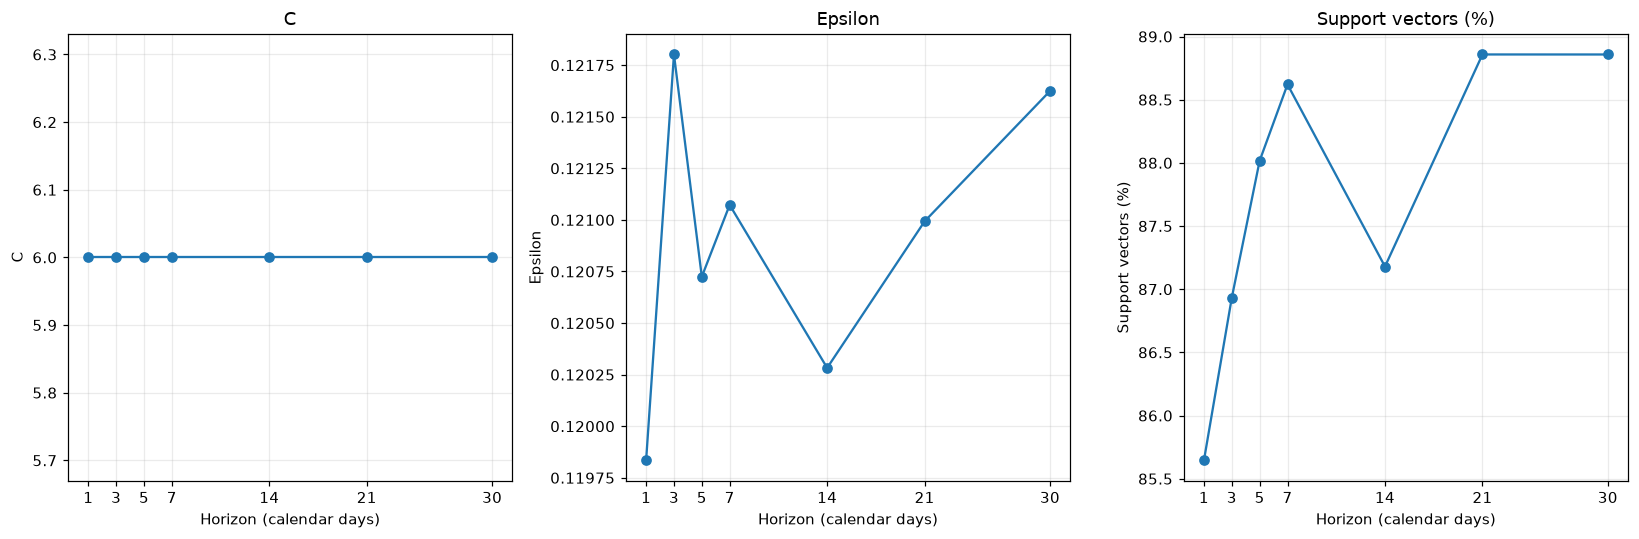

In [20]:
for h in HORIZONS:
    group=forecasts.loc[forecasts['h'].eq(h)]
    fig,ax=plt.subplots(figsize=(13,5))
    ax.plot(group['target_date'],group['actual'],label='Actual',color='black',linewidth=1.3)
    ax.plot(group['target_date'],group['svr_fc'],label=f'SVR h={h}',linewidth=1)
    if SHOW_NAIVE_REFERENCE:
        ax.plot(group['target_date'],group['price_origin'],label='Naive reference only',alpha=0.5)
    ax.set(title=f'SVR rolling-origin forecast - {h} calendar days',xlabel='Target date',ylabel='Price (USD)')
    ax.legend(); save_figure(fig,f'06_forecast_h{h}.png')
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,metric,unit in zip(axes,['RMSE','MAPE'],['USD','%']):
    ax.plot(evaluation['h'],evaluation[metric],marker='o')
    ax.set(title=metric,xlabel='Horizon (calendar days)',ylabel=f'{metric} ({unit})',xticks=HORIZONS)
save_figure(fig,'07_error_vs_horizon.png')
fig,axes=plt.subplots(1,3,figsize=(15,5))
for ax,column,label in zip(axes,['C','epsilon','SV_pct'],['C','Epsilon','Support vectors (%)']):
    ax.plot(hyperparameters['h'],hyperparameters[column],marker='o')
    ax.set(title=label,xlabel='Horizon (calendar days)',ylabel=label,xticks=HORIZONS)
save_figure(fig,'08_hyperparameters_by_horizon.png')

## Step 11 - Assumption and Process Checks
Group A structural and fitting requirements must pass. Train/test return mean and SD are reported descriptively because no acceptance threshold was supplied; no test distribution result changes the model.
Group B uses only h=1 test errors in unscaled log-return units. Higher-horizon targets overlap, so their autocorrelation would partly arise by construction. Diagnostics are reporting-only, not model rejection criteria.


C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,group,check,statistic,p_value,pass/fail,note
0,A,Chronological unique dates,1.000000,NaN,PASS,
1,A,Input scaler excludes test,1516.000000,NaN,PASS,
2,A,Train features/targets exclude test: h=1,1516.000000,NaN,PASS,
3,A,Target scaler excludes test: h=1,1456.000000,NaN,PASS,
4,A,Hyperparameters use train only: h=1,1456.000000,NaN,PASS,
5,A,Fit successful: h=1,85.645604,NaN,PASS,Statistic=%SV; n_SV=1247; no ConvergenceWarnin...
6,A,Model/scalers fixed in inference: h=1,1.000000,NaN,PASS,
7,A,Train features/targets exclude test: h=3,1516.000000,NaN,PASS,
8,A,Target scaler excludes test: h=3,1454.000000,NaN,PASS,
9,A,Hyperparameters use train only: h=3,1454.000000,NaN,PASS,


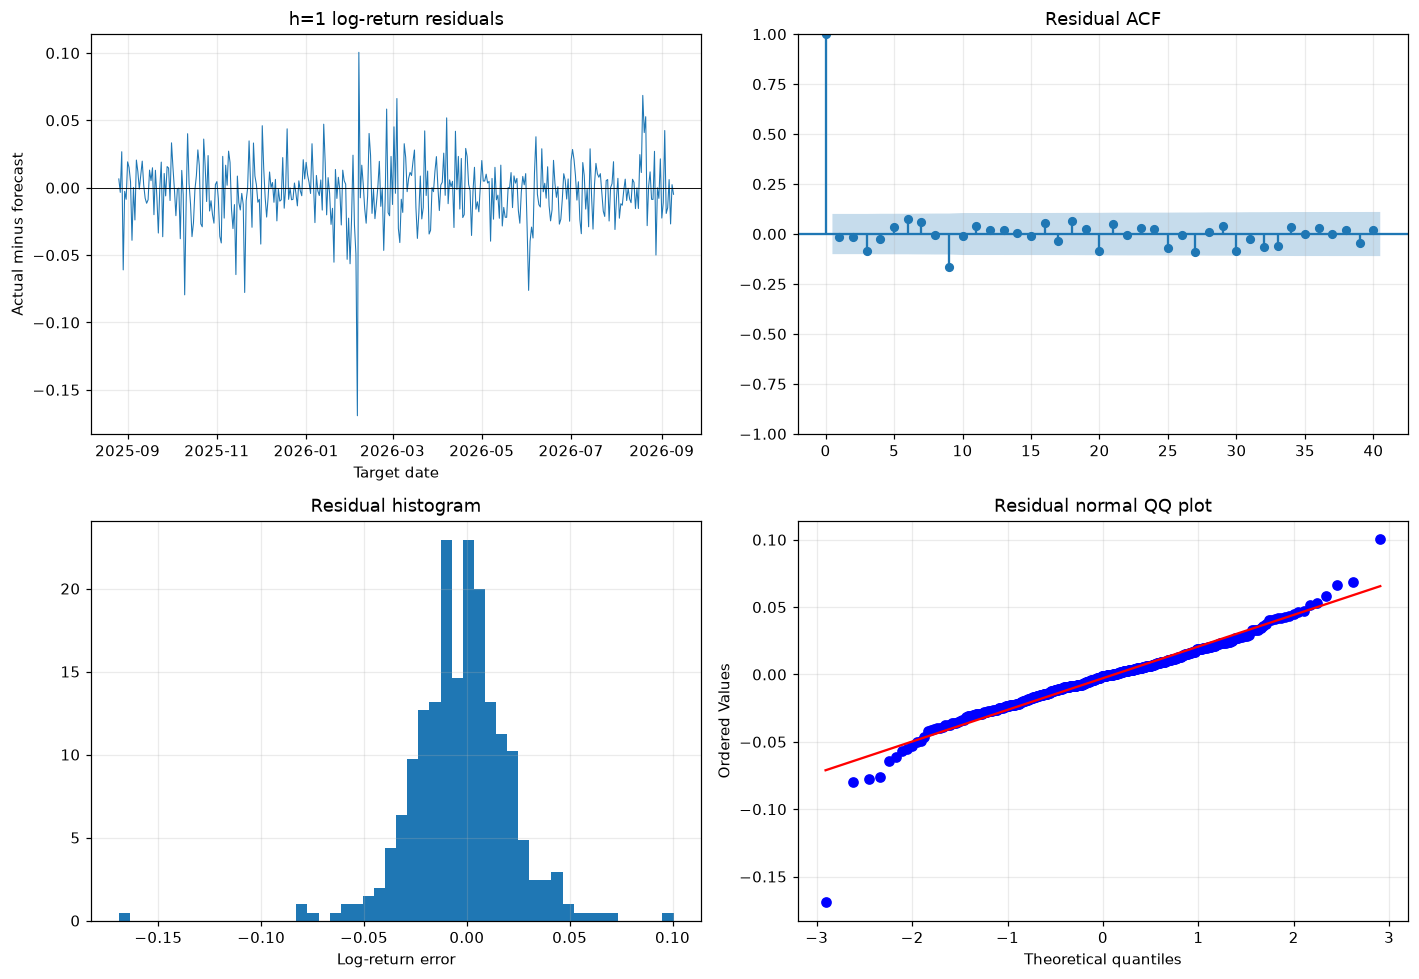

In [21]:
checks=[]
def add_check(group,check,statistic=np.nan,p_value=np.nan,passed=None,note=''):
    checks.append({'group':group,'check':check,'statistic':statistic,'p_value':p_value,
        'pass/fail':'REPORTED' if passed is None else ('PASS' if bool(passed) else 'FAIL'),'note':note})
ordered=df.index.is_monotonic_increasing and df.index.is_unique
add_check('A','Chronological unique dates',int(ordered),passed=ordered)
assert ordered
add_check('A','Input scaler excludes test',int(scaler_x_fit_indices.max()),
    passed=scaler_x_fit_indices.max()<=TRAIN_END_IDX)
for h in HORIZONS:
    batch=training[h]
    no_leak=batch['input_idx'].max()<=TRAIN_END_IDX and batch['target_idx'].max()<=TRAIN_END_IDX
    scaler_only_train=int(scaler_y[h].n_samples_seen_)==len(batch['origins']) and no_leak
    hyper_only_train=np.array_equal(hyperparameter_origins[h],batch['origins']) and no_leak
    fit_row=fit_audit.set_index('h').loc[h]
    fit_ok=not fit_row['convergence_warning'] and fit_row['fit_status']==0 and 0<=fit_row['SV_pct']<=100
    unchanged=joblib.hash((models[h],scaler_x,scaler_y[h]))==frozen_hashes[h]
    add_check('A',f'Train features/targets exclude test: h={h}',int(batch['target_idx'].max()),passed=no_leak)
    add_check('A',f'Target scaler excludes test: h={h}',int(scaler_y[h].n_samples_seen_),passed=scaler_only_train)
    add_check('A',f'Hyperparameters use train only: h={h}',len(hyperparameter_origins[h]),passed=hyper_only_train)
    add_check('A',f'Fit successful: h={h}',float(fit_row['SV_pct']),passed=fit_ok,
        note=f'Statistic=%SV; n_SV={fit_row.n_SV}; no ConvergenceWarning; status={fit_row.fit_status}')
    add_check('A',f'Model/scalers fixed in inference: h={h}',int(unchanged),passed=unchanged)
    assert no_leak and scaler_only_train and hyper_only_train and fit_ok and unchanged
train_stats=split_summary.set_index('split').loc['Train']
test_stats=split_summary.set_index('split').loc['Test']
add_check('A','Train/test return mean and SD',test_stats.log_ret_std/train_stats.log_ret_std,
    note=f'Train mean={train_stats.log_ret_mean:.6g}, SD={train_stats.log_ret_std:.6g}; '
    f'Test mean={test_stats.log_ret_mean:.6g}, SD={test_stats.log_ret_std:.6g}. '
    'Statistic=Test/Train SD ratio; no supplied acceptance threshold.')
h1=forecasts.loc[forecasts['h'].eq(1)]
e=np.log(h1['actual'].to_numpy()/h1['price_origin'].to_numpy())-predicted_cumulative_returns[1]
assert len(e)==n_test==380 and np.isfinite(e).all()
for lag,row in acorr_ljungbox(e,lags=[10,20,30],return_df=True).iterrows():
    add_check('B',f'Ljung-Box lag {lag}',row.lb_stat,row.lb_pvalue,row.lb_pvalue>ALPHA,
              'Significant p-value indicates residual autocorrelation; reporting only')
stat,pv=stats.ttest_1samp(e,0)
add_check('B','Residual mean = 0',stat,pv,pv>ALPHA,f'Mean error={e.mean():.6g}; reporting only')
stat,pv,_,_=het_arch(e,nlags=10)
add_check('B','ARCH LM (10 lags)',stat,pv,pv>ALPHA,'Significant p-value indicates changing error variance; reporting only')
stat,pv,skew,kurt=jarque_bera(e)
add_check('B','Jarque-Bera',stat,pv,pv>ALPHA,f'Skew={skew:.4g}, kurtosis={kurt:.4g}; reporting only')
assumption_checks=pd.DataFrame(checks)
save_table(assumption_checks,'assumption_checks.csv')
save_table(pd.DataFrame(dict(target_date=h1['target_date'].to_numpy(),residual_log_return=e)),'residuals_h1.csv')
display(assumption_checks)
fig,axes=plt.subplots(2,2,figsize=(13,9))
axes[0,0].plot(h1['target_date'],e,linewidth=0.7); axes[0,0].axhline(0,color='black',linewidth=0.6)
axes[0,0].set(title='h=1 log-return residuals',xlabel='Target date',ylabel='Actual minus forecast')
plot_acf(e,lags=40,ax=axes[0,1]); axes[0,1].set_title('Residual ACF')
axes[1,0].hist(e,bins=50,density=True); axes[1,0].set(title='Residual histogram',xlabel='Log-return error')
stats.probplot(e,dist='norm',plot=axes[1,1]); axes[1,1].set_title('Residual normal QQ plot')
save_figure(fig,'09_residual_diagnostics.png')

## Step 12 - Summary
Report the fixed design, analytical parameter values, process checks, reporting-only residual diagnostics, and RMSE/MAPE at every horizon.
Training-target RMSE in standardized units is a fitting diagnostic; holdout performance uses USD forecasts. Test metrics are not used to revise any parameter.


In [22]:
lines=['### SVR results from this execution','',
    f'RBF kernel; numerical gamma selected per horizon; lookback={LOOKBACK}; direct strategy with {len(HORIZONS)} fixed models.',
    f'Chronological Train/Test={n_train}/{n_test} raw observations. No validation; candidate parameters ranked by Train price RMSE only.',
    'Candidates multiply the Train analytical C/epsilon/gamma reference values; rank 1 is selected by Train price RMSE per horizon.',
    'See section 7.1 for Top 5 candidates; selected numerical gamma and C/epsilon are recorded before Test.',
    '', '**Selected hyperparameters and train fitting diagnostics**','',
    '| h | Train samples | C | sigma_hat | epsilon | gamma | %SV | Train RMSE (scaled target) |',
    '|---:|---:|---:|---:|---:|---:|---:|---:|']
for row in hyperparameters.itertuples(index=False):
    lines.append(f'| {row.h} | {row.n_train} | {row.C:.6g} | {row.sigma_hat:.6g} | '
        f'{row.epsilon:.6g} | {row.gamma_value:.6g} | {row.SV_pct:.2f} | {row.train_RMSE_scaled:.4f} |')
for group in ['A','B']:
    lines += ['',f'**Group {group} checks**']
    for row in assumption_checks.loc[assumption_checks['group'].eq(group)].to_dict('records'):
        ptext=f', p={row["p_value"]:.6g}' if pd.notna(row['p_value']) else ''
        lines.append(f'- {row["check"]}: {row["pass/fail"]}{ptext}. {row["note"]}')
lines += ['', '**Test performance in USD**','', '| h (days) | n | RMSE (USD) | MAPE (%) |','|---:|---:|---:|---:|']
for row in evaluation.itertuples(index=False):
    lines.append(f'| {row.h} | {row.n_points} | {row.RMSE:,.2f} | {row.MAPE:.2f} |')
for metric in ['RMSE','MAPE']:
    trend='increases at every adjacent requested horizon' if (np.diff(evaluation[metric])>0).all() else 'does not increase monotonically across every requested horizon'
    lines.append(f'- {metric} {trend}.')
lines += ['', '**Future forecasts from the final observed date**']
for row in future_forecasts.itertuples(index=False):
    lines.append(f'- h={row.h}: origin={row.origin_date.date()}, target={row.target_date.date()}, forecast={row.svr_fc:,.2f} USD.')
lines += ['', '**Limitations**',
    '- The analytical noise prescription assumes relatively regular noise; BTC returns have fat tails and volatility clustering. The heuristic is not guaranteed optimal.',
    '- The model is univariate and does not observe news, policy changes, macroeconomic inputs or unexpected events.',
    f'- Test price levels span {df["Price"].iloc[n_train:].min():,.0f}-{df["Price"].iloc[n_train:].max():,.0f} USD; this is a description, not a formal break test.',
    '- Models and scalers were fitted once on train; there is no refitting during test or future inference.',
    '- Target horizons overlap; sample sizes and target dates differ across horizons. Only h=1 residual diagnostics are reported.',
    '- No validation estimate exists. In-sample fit quality does not establish holdout forecast accuracy.',
    '- Train/test return-scale comparability has no supplied pass threshold and is reported descriptively.',
    '- MAPE is percentage error, not statistical accuracy. No calibrated prediction interval is supplied.',
    '', f'Outputs: `{OUTPUT_DIR}`.']
summary_markdown='\n'.join(lines)
display(Markdown(summary_markdown))
(OUTPUT_DIR/'summary.md').write_text(summary_markdown,encoding='utf-8')
required_tables=['split_summary.csv','svr_hyperparameters.csv','forecasts_long.csv','evaluation_by_horizon.csv',
    'assumption_checks.csv','future_forecast_by_horizon.csv',*[f'forecasts_h{h}.csv' for h in HORIZONS]]
required_figures=['01_raw_price_volume.png','02_log_return.png','03_return_distribution.png',
    '04_acf_log_return.png','05_train_test_split.png',*[f'06_forecast_h{h}.png' for h in HORIZONS],
    '07_error_vs_horizon.png','08_hyperparameters_by_horizon.png','09_residual_diagnostics.png']
required_tables += [f'future_forecast_daily_{days}d.csv' for days in DAILY_FORECAST_WINDOWS]
assert all((TABLE_DIR/file).is_file() for file in required_tables)
assert all((FIGURE_DIR/file).is_file() for file in required_figures)
assert all((MODEL_DIR/f'svr_h{h}.joblib').is_file() and (MODEL_DIR/f'scaler_y_h{h}.joblib').is_file() for h in HORIZONS)
assert all(joblib.hash((models[h],scaler_x,scaler_y[h]))==frozen_hashes[h] for h in HORIZONS)
print('Completed: all required outputs saved; models and scalers stayed fixed.')
display(Markdown('**Current experiment:** Top 5 ranked by in-sample Train price RMSE; rank 1 selected per horizon. No validation/CV. Test/future periods were already inspected; this rerun is retrospective.'))


### SVR results from this execution

RBF kernel; numerical gamma selected per horizon; lookback=60; direct strategy with 7 fixed models.
Chronological Train/Test=1517/380 raw observations. No validation; candidate parameters ranked by Train price RMSE only.
Candidates multiply the Train analytical C/epsilon/gamma reference values; rank 1 is selected by Train price RMSE per horizon.
See section 7.1 for Top 5 candidates; selected numerical gamma and C/epsilon are recorded before Test.

**Selected hyperparameters and train fitting diagnostics**

| h | Train samples | C | sigma_hat | epsilon | gamma | %SV | Train RMSE (scaled target) |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 1 | 1456 | 6 | 1.12954 | 0.119835 | 0.0330171 | 85.65 | 0.1189 |
| 3 | 1454 | 6 | 1.14741 | 0.121802 | 0.0329846 | 86.93 | 0.1206 |
| 5 | 1452 | 6 | 1.13658 | 0.120725 | 0.0329519 | 88.02 | 0.1168 |
| 7 | 1450 | 6 | 1.13918 | 0.121072 | 0.0329193 | 88.62 | 0.1167 |
| 14 | 1443 | 6 | 1.12939 | 0.120283 | 0.0328013 | 87.18 | 0.1152 |
| 21 | 1436 | 6 | 1.13368 | 0.120993 | 0.0326809 | 88.86 | 0.1164 |
| 30 | 1427 | 6 | 1.13651 | 0.121624 | 0.0325329 | 88.86 | 0.1171 |

**Group A checks**
- Chronological unique dates: PASS. 
- Input scaler excludes test: PASS. 
- Train features/targets exclude test: h=1: PASS. 
- Target scaler excludes test: h=1: PASS. 
- Hyperparameters use train only: h=1: PASS. 
- Fit successful: h=1: PASS. Statistic=%SV; n_SV=1247; no ConvergenceWarning; status=0
- Model/scalers fixed in inference: h=1: PASS. 
- Train features/targets exclude test: h=3: PASS. 
- Target scaler excludes test: h=3: PASS. 
- Hyperparameters use train only: h=3: PASS. 
- Fit successful: h=3: PASS. Statistic=%SV; n_SV=1264; no ConvergenceWarning; status=0
- Model/scalers fixed in inference: h=3: PASS. 
- Train features/targets exclude test: h=5: PASS. 
- Target scaler excludes test: h=5: PASS. 
- Hyperparameters use train only: h=5: PASS. 
- Fit successful: h=5: PASS. Statistic=%SV; n_SV=1278; no ConvergenceWarning; status=0
- Model/scalers fixed in inference: h=5: PASS. 
- Train features/targets exclude test: h=7: PASS. 
- Target scaler excludes test: h=7: PASS. 
- Hyperparameters use train only: h=7: PASS. 
- Fit successful: h=7: PASS. Statistic=%SV; n_SV=1285; no ConvergenceWarning; status=0
- Model/scalers fixed in inference: h=7: PASS. 
- Train features/targets exclude test: h=14: PASS. 
- Target scaler excludes test: h=14: PASS. 
- Hyperparameters use train only: h=14: PASS. 
- Fit successful: h=14: PASS. Statistic=%SV; n_SV=1258; no ConvergenceWarning; status=0
- Model/scalers fixed in inference: h=14: PASS. 
- Train features/targets exclude test: h=21: PASS. 
- Target scaler excludes test: h=21: PASS. 
- Hyperparameters use train only: h=21: PASS. 
- Fit successful: h=21: PASS. Statistic=%SV; n_SV=1276; no ConvergenceWarning; status=0
- Model/scalers fixed in inference: h=21: PASS. 
- Train features/targets exclude test: h=30: PASS. 
- Target scaler excludes test: h=30: PASS. 
- Hyperparameters use train only: h=30: PASS. 
- Fit successful: h=30: PASS. Statistic=%SV; n_SV=1268; no ConvergenceWarning; status=0
- Model/scalers fixed in inference: h=30: PASS. 
- Train/test return mean and SD: REPORTED. Train mean=0.00078411, SD=0.0284756; Test mean=-0.000897492, SD=0.0229077. Statistic=Test/Train SD ratio; no supplied acceptance threshold.

**Group B checks**
- Ljung-Box lag 10: PASS, p=0.0597597. Significant p-value indicates residual autocorrelation; reporting only
- Ljung-Box lag 20: PASS, p=0.20066. Significant p-value indicates residual autocorrelation; reporting only
- Ljung-Box lag 30: PASS, p=0.20902. Significant p-value indicates residual autocorrelation; reporting only
- Residual mean = 0: FAIL, p=0.0261165. Mean error=-0.00276999; reporting only
- ARCH LM (10 lags): FAIL, p=0.000177831. Significant p-value indicates changing error variance; reporting only
- Jarque-Bera: FAIL, p=3.72017e-157. Skew=-0.7203, kurtosis=9.59; reporting only

**Test performance in USD**

| h (days) | n | RMSE (USD) | MAPE (%) |
|---:|---:|---:|---:|
| 1 | 380 | 2,010.94 | 1.75 |
| 3 | 378 | 3,662.68 | 3.32 |
| 5 | 376 | 4,737.94 | 4.29 |
| 7 | 374 | 5,827.10 | 5.33 |
| 14 | 367 | 8,820.22 | 8.28 |
| 21 | 360 | 11,627.14 | 11.13 |
| 30 | 351 | 15,556.48 | 15.12 |
- RMSE increases at every adjacent requested horizon.
- MAPE increases at every adjacent requested horizon.

**Future forecasts from the final observed date**
- h=1: origin=2026-09-09, target=2026-09-10, forecast=77,704.58 USD.
- h=3: origin=2026-09-09, target=2026-09-12, forecast=78,177.78 USD.
- h=5: origin=2026-09-09, target=2026-09-14, forecast=78,481.90 USD.
- h=7: origin=2026-09-09, target=2026-09-16, forecast=79,868.42 USD.
- h=14: origin=2026-09-09, target=2026-09-23, forecast=83,043.84 USD.
- h=21: origin=2026-09-09, target=2026-09-30, forecast=82,846.36 USD.
- h=30: origin=2026-09-09, target=2026-10-09, forecast=83,218.76 USD.

**Limitations**
- The analytical noise prescription assumes relatively regular noise; BTC returns have fat tails and volatility clustering. The heuristic is not guaranteed optimal.
- The model is univariate and does not observe news, policy changes, macroeconomic inputs or unexpected events.
- Test price levels span 58,631-124,725 USD; this is a description, not a formal break test.
- Models and scalers were fitted once on train; there is no refitting during test or future inference.
- Target horizons overlap; sample sizes and target dates differ across horizons. Only h=1 residual diagnostics are reported.
- No validation estimate exists. In-sample fit quality does not establish holdout forecast accuracy.
- Train/test return-scale comparability has no supplied pass threshold and is reported descriptively.
- MAPE is percentage error, not statistical accuracy. No calibrated prediction interval is supplied.

Outputs: `C:\Users\User\Desktop\PROJECT_2026\OUTPUT\outputs_svr`.

Completed: all required outputs saved; models and scalers stayed fixed.


**Current experiment:** Top 5 ranked by in-sample Train price RMSE; rank 1 selected per horizon. No validation/CV. Test/future periods were already inspected; this rerun is retrospective.

### Summary of the current experiment

The generated summary above contains the current Train-ranked SVR results. Earlier saved numerical summaries are superseded.

### Method references
Cherkassky, V., & Ma, Y. (2004). Practical selection of SVM parameters and noise estimation for SVM regression. Neural Networks, 17(1), 113-126. [DOI](https://doi.org/10.1016/S0893-6080(03)00169-2).
The notebook implements the formula prescription provided in the task, rather than claiming it is a universally optimal parameter choice.
[scikit-learn SVR and gamma='scale'](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html).
